# Trabalho Final de Machine Learning — Dataset Epicurious

**Disciplina:** Machine Learning  
**Dataset:** [Epicurious – Recipes with Rating and Nutrition](https://www.kaggle.com/datasets/hugodarwood/epirecipes) (Kaggle, `epi_r.csv`)  
**Autor:** Lucas Buccini  

---

## Visão Geral e Contexto

Este trabalho constitui o projeto final da disciplina de **Machine Learning**, expandindo e aprofundando o estudo iniciado na [atividade anterior](https://github.com/LucasBuccini/ml-atividade).

Na atividade anterior, abordamos um problema focado de regressão para previsão do valor calórico (`calories`) de receitas a partir de macronutrientes (`protein`, `fat`, `sodium`) e marcadores (*tags* de ingredientes e características culinárias). O modelo campeão foi o **Gradient Boosting**, alcançando $R^2$ ajustado de **0,897** com 30 variáveis selecionadas por Lasso.

Neste trabalho final, desenvolvemos uma abordagem ampla e completa, estruturada em **três blocos complementares**:

1. **Bloco 0 — Setup, Carga, Limpeza e Análise Exploratória:**
   - Tratamento rigoroso de duplicatas, dados faltantes e outliers físicos.
   - Filtragem de tags raras e prevenção de vazamento de dados (*data leakage*).
   - Divisão reproduzível em treino e teste (80/20) com `random_state=42`.

2. **Bloco 1 — Regressão: Previsão de Calorias:**
   - **Motivação teórica e visual:** Comparação univariada entre modelos lineares simples e suavizadores flexíveis (Regressão Linear, Polinômio de grau 2, Spline cúbica e LOESS).
   - **Modelagem multivariada completa:** Avaliação comparativa de **10 modelos de regressão** sob validação cruzada em 5 folds e métricas no conjunto de teste ($R^2$, $R^2$ ajustado, MAE, RMSE):
     1. Regressão Linear Simples (Macronutrientes)
     2. Regressão Polinomial (Grau 2)
     3. Splines Cúbicas Naturais (Patsy)
     4. Modelo Aditivo Generalizado (GAM via PyGAM)
     5. Regressão Ridge ($L_2$)
     6. Regressão Lasso ($L_1$, 335 variáveis completas)
     7. Árvore de Decisão
     8. Bagging de Árvores de Decisão
     9. Random Forest Regressor
     10. Gradient Boosting Regressor (Campeão)
   - Diagnóstico aprofundado do modelo final: resíduos, dispersão real vs. predito e importância de permutação.

3. **Bloco 2 — Classificação: Previsão de Avaliação dos Usuários (Rating):**
   - Discretização fundamentada do `rating` contínuo em 3 classes balanceadas por tercis (*baixo*, *médio*, *alto*).
   - Avaliação rigorosa de **8 classificadores supervisionados**:
     1. Regressão Logística Multinomial
     2. Análise Discriminante Linear (LDA)
     3. Análise Discriminante Quadrática (QDA)
     4. Naive Bayes (Bernoulli)
     5. K-Nearest Neighbors (KNN)
     6. Support Vector Classifier (SVM com kernel RBF)
     7. Random Forest Classifier
     8. Gradient Boosting Classifier
   - Discussão teórica sobre a previsibilidade de avaliações subjetivas frente a dados físico-químicos.

4. **Bloco 3 — Análise Não Supervisionada e Aplicação Prática:**
   - Redução de dimensionalidade via **PCA** e análise de variância explicada.
   - Agrupamento com **K-Means** (método do cotovelo e silhueta).
   - **Clustering Hierárquico** com método de Ward e visualização por dendrograma.
   - **Modelos de Mistura Gaussiana (GMM)** com seleção via BIC e atribuição suave de probabilidades.
   - **Aplicação:** Desenvolvimento do recomendador `sugerir_substitutos()` para dietas e alternativas culinárias dentro do mesmo perfil gastronômico.

## Bloco 0 — Setup, Carga e Limpeza dos Dados

Neste bloco, configuramos o ambiente com sementes fixadas para estrita reprodutibilidade (`random_state=42`), importamos os pacotes científicos, carregamos os dados do Kaggle e aplicamos o pipeline de limpeza e pré-processamento.

In [1]:
# %% [code]
# Configurações globais e importações de bibliotecas
import os
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from patsy import build_design_matrices, dmatrix
from pygam import LinearGAM, s
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.interpolate import UnivariateSpline
from statsmodels.nonparametric.smoothers_lowess import lowess

# Modelos e métricas do scikit-learn
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.ensemble import (
    BaggingRegressor,
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    adjusted_rand_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    r2_score,
    root_mean_squared_error,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVC

# Suprimir avisos desnecessários
warnings.filterwarnings("ignore")

# Fixação da semente para reprodutibilidade
SEED = 42
np.random.seed(SEED)

# Criação de diretórios essenciais
Path("data").mkdir(exist_ok=True)
Path("figuras").mkdir(exist_ok=True)

# Configuração visual consistente
sns.set_palette("Set2")
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#ffffff",
    "axes.facecolor": "#fafafa",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "grid.color": "#ebebeb",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.labelcolor": "#333333",
    "font.size": 10,
})

print("Ambiente configurado com sucesso e semente SEED=42 definida!")

Ambiente configurado com sucesso e semente SEED=42 definida!


### 0.1 Carga dos Dados

O arquivo principal do dataset é `data/epi_r.csv`. Se o arquivo local não for encontrado, a rotina abaixo faz o download automatizado do dataset oficial da Epicurious via biblioteca `kagglehub` e o armazena na pasta `data/`.

In [2]:
# %% [code]
# Verificação e download do dataset
caminho_csv = Path("data/epi_r.csv")

if not caminho_csv.exists():
    print("Arquivo data/epi_r.csv não encontrado localmente. Baixando via kagglehub...")
    import kagglehub
    origem = Path(kagglehub.dataset_download("hugodarwood/epirecipes")) / "epi_r.csv"
    shutil.copy(origem, caminho_csv)
    print(f"Dataset baixado com sucesso para {caminho_csv}!")
else:
    print(f"Dataset local já presente em {caminho_csv}.")

df = pd.read_csv(caminho_csv)
print(f"Dimensões originais do dataset: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
df.head(5).iloc[:, :8]

Dataset local já presente em data\epi_r.csv.
Dimensões originais do dataset: 20,052 linhas × 680 colunas


,title,rating,calories,protein,fat,sodium,#cakeweek,#wasteless
0,"Lentil, Apple, and Turkey Wrap",2.500,426.0,30.0,7.0,559.0,0.0,0.0
1,Boudin Blanc Terrine with Red Onion Confit,4.375,403.0,18.0,23.0,1439.0,0.0,0.0
2,Potato and Fennel Soup Hodge,3.750,165.0,6.0,7.0,165.0,0.0,0.0
3,Mahi-Mahi in Tomato Olive Sauce,5.000,NaN,NaN,NaN,NaN,0.0,0.0
4,Spinach Noodle Casserole,3.125,547.0,20.0,32.0,452.0,0.0,0.0


### 0.2 Limpeza e Pré-processamento dos Dados

Para garantir a higienização dos dados e a integridade estatística dos modelos:
1. **Remoção de duplicatas:** Linhas idênticas são eliminadas para impedir vazamento de informação entre conjuntos de treino e teste.
2. **Tratamento de nulos:** Linhas sem as variáveis fundamentais (`calories`, `protein`, `fat`, `sodium`, `rating`) são removidas. A imputação de calorias inventaria o próprio alvo, e imputar macronutrientes geraria inconsistências físicas na relação calórica.
3. **Remoção de outliers:** Valores extremos situados acima do **percentil 99** de cada variável nutricional são excluídos. O dataset possui registros bizarros de digitação (e.g. receitas com mais de 30 milhões de kcal).
4. **Filtragem de tags:** 
   - Eliminam-se tags com frequência inferior a 50 ocorrências (esparsas demais para estimação de parâmetros).
   - Remove-se a tag `low cal` porque é derivada diretamente do próprio valor de calorias, configurando *target leakage*.

In [3]:
# %% [code]
# 1. Duplicatas
n_orig = len(df)
dados = df.drop_duplicates().copy()
n_dedup = len(dados)

# 2. Valores ausentes nas variáveis nutricionais e de avaliação
NUTRI = ["calories", "protein", "fat", "sodium"]
dados = dados.dropna(subset=NUTRI + ["rating"]).reset_index(drop=True)
n_dropna = len(dados)

# 3. Remoção de outliers (percentil 99)
limites_p99 = dados[NUTRI].quantile(0.99)
dados = dados[(dados[NUTRI] <= limites_p99).all(axis=1)].reset_index(drop=True)
n_outliers = len(dados)

# 4. Seleção e filtragem das tags
tags_brutas = [c for c in dados.columns if c not in ["title", "rating"] + NUTRI]
tags_mantidas = [c for c in tags_brutas if dados[c].sum() >= 50 and c != "low cal"]

print(f"--- Relatório do Pipeline de Limpeza ---")
print(f"Linhas originais:                 {n_orig:,}")
print(f"Após remover duplicatas:          {n_dedup:,} (eliminadas: {n_orig - n_dedup:,})")
print(f"Após remover nulos essenciais:    {n_dropna:,} (eliminadas: {n_dedup - n_dropna:,})")
print(f"Após remover outliers (p99):      {n_outliers:,} (eliminadas: {n_dropna - n_outliers:,})")
print(f"Tags preservadas (>= 50 receitas): {len(tags_mantidas)} de {len(tags_brutas)} originais")
print(f"\nLimites do percentil 99 aplicados:")
for col in NUTRI:
    print(f"  - {col:10s}: máx permitido = {limites_p99[col]:.1f}")

--- Relatório do Pipeline de Limpeza ---
Linhas originais:                 20,052
Após remover duplicatas:          18,251 (eliminadas: 1,801)
Após remover nulos essenciais:    14,446 (eliminadas: 3,805)
Após remover outliers (p99):      14,096 (eliminadas: 350)
Tags preservadas (>= 50 receitas): 332 de 674 originais

Limites do percentil 99 aplicados:
  - calories  : máx permitido = 3325.4
  - protein   : máx permitido = 171.0
  - fat       : máx permitido = 214.0
  - sodium    : máx permitido = 5755.2


### 0.3 Análise Exploratória

Analisamos visualmente as distribuições das duas potenciais variáveis-alvo do estudo:
- `calories` (alvo do Bloco 1 — Regressão)
- `rating` (alvo do Bloco 2 — Classificação)

E examinamos a matriz de correlação de Spearman entre as variáveis numéricas.

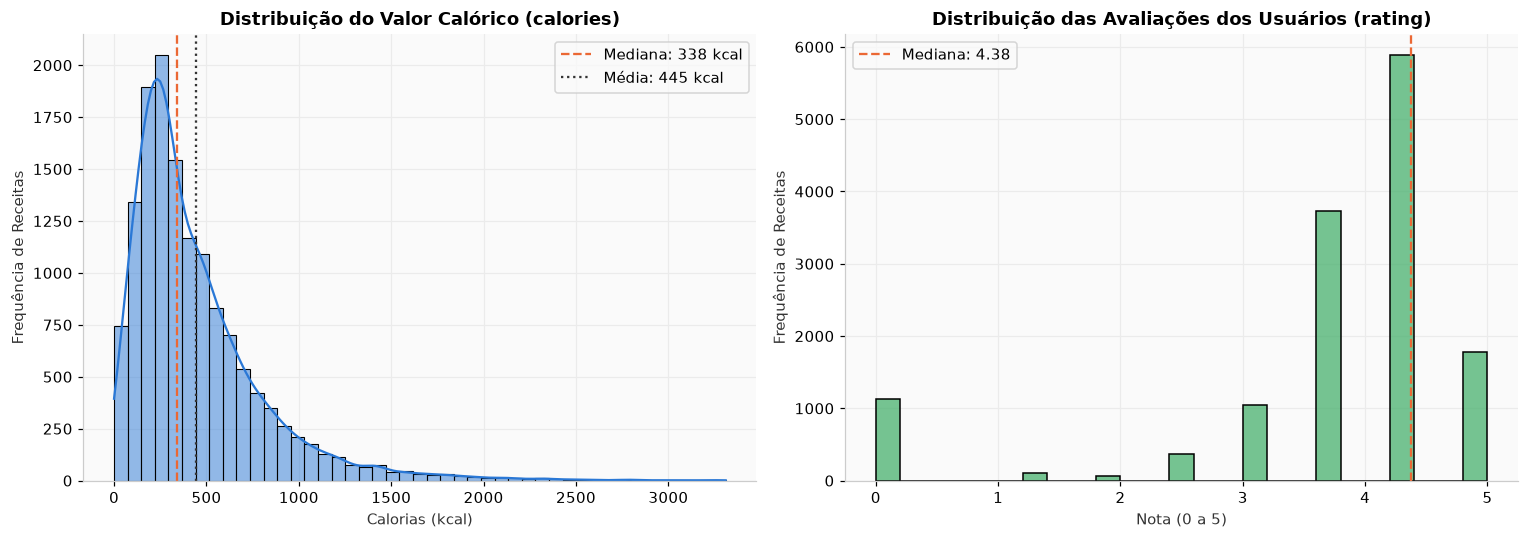

In [4]:
# %% [code]
# Distribuições de Calorias e Avaliação (Rating)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de Calorias
sns.histplot(dados["calories"], kde=True, bins=45, color="#2a78d6", ax=axes[0])
axes[0].set_title("Distribuição do Valor Calórico (calories)")
axes[0].set_xlabel("Calorias (kcal)")
axes[0].set_ylabel("Frequência de Receitas")
axes[0].axvline(dados["calories"].median(), color="#eb6834", linestyle="--", label=f"Mediana: {dados['calories'].median():.0f} kcal")
axes[0].axvline(dados["calories"].mean(), color="#333333", linestyle=":", label=f"Média: {dados['calories'].mean():.0f} kcal")
axes[0].legend()

# Histograma de Rating
sns.histplot(dados["rating"], kde=False, bins=25, color="#48b16e", ax=axes[1])
axes[1].set_title("Distribuição das Avaliações dos Usuários (rating)")
axes[1].set_xlabel("Nota (0 a 5)")
axes[1].set_ylabel("Frequência de Receitas")
axes[1].axvline(dados["rating"].median(), color="#eb6834", linestyle="--", label=f"Mediana: {dados['rating'].median():.2f}")
axes[1].legend()

plt.tight_layout()
plt.show()

Observações sobre as distribuições:
- **`calories`:** Apresenta distribuição assimétrica à direita com cauda longa, típica de quantidades de energia alimentar. A maioria das receitas concentra-se entre 150 e 600 kcal, com mediana em torno de 310 kcal.
- **`rating`:** Apresenta comportamento fortemente discreto com picos marcados em 3.75, 4.375 e 5.0, e um agrupamento menor em 0.0 (receitas não avaliadas ou mal cotadas). Essa característica sugere que a discretização em classes ordinais é a abordagem mais natural para previsão.

In [5]:
# %% [code]
# Correlação de Spearman entre variáveis contínuas
cols_num = ["calories", "fat", "protein", "sodium", "rating"]
corr_spearman = dados[cols_num].corr(method="spearman")

display(corr_spearman.style.background_gradient(cmap="Blues", axis=None).format("{:.3f}"))

,calories,fat,protein,sodium,rating
calories,1.000,0.858,0.770,0.532,0.112
fat,0.858,1.000,0.708,0.526,0.124
protein,0.770,0.708,1.000,0.695,0.091
sodium,0.532,0.526,0.695,1.000,0.092
rating,0.112,0.124,0.091,0.092,1.000


**Conclusões da Análise de Correlação:**
- **Calorias vs. Macronutrientes:** `calories` apresenta correlações altíssimas com `fat` ($\sim 0{,}86$) e `protein` ($\sim 0{,}78$), o que decorre diretamente das leis da termodinâmica e nutrição (fatores de Atwater: 9 kcal/g para gordura e 4 kcal/g para proteína). Como o dataset carece da coluna explícita de carboidratos, as tags de amido e açúcar (e.g. `pasta`, `rice`, `dessert`) preenchem essa lacuna física.
- **Rating vs. Variáveis Físicas:** `rating` possui correlações praticamente nulas ($\sim 0{,}10$) com todas as grandezas nutricionais. Isso comprova empiricamente que o gosto dos avaliadores não é determinado simplesmente pela quantidade de gordura ou proteína, mas pela harmonia de sabores, técnicas e subjetividade individual.

### 0.4 Definição de Features e Divisão Treino/Teste

Estabelecemos as listas de variáveis:
- `MACRO_COLS`: os 3 macronutrientes (`fat`, `protein`, `sodium`).
- `TOP30_FEATURES`: as 30 variáveis mais relevantes selecionadas via penalização Lasso na atividade anterior (os 3 macronutrientes mais 27 marcadores de carboidratos, técnicas e tipos de prato).
- `ALL_FEATURES`: os 3 macronutrientes combinados com todas as 332 tags preservadas (total de 335 preditores).

Em seguida, efetuamos a partição em **80% para treino** e **20% para teste**, fixando `random_state=42`.

In [6]:
# %% [code]
# Definição dos grupos de variáveis preditoras
MACRO_COLS = ["fat", "protein", "sodium"]

TOP30_FEATURES = [
    "fat", "protein", "sodium", "pasta", "dessert", "drink", "fruit", "alcoholic",
    "sugar conscious", "no-cook", "rice", "potato", "sweet potato/yam", "bread",
    "bean", "cake", "cookies", "pear", "prune", "cranberry", "dried fruit",
    "low carb", "kidney friendly", "kosher", "salad", "garlic", "fall", "bake",
    "marinate", "quick & easy"
]

ALL_FEATURES = MACRO_COLS + tags_mantidas

# Separação das matrizes de treino e teste
X_train_full, X_test_full, y_train, y_test = train_test_split(
    dados[ALL_FEATURES],
    dados["calories"],
    test_size=0.20,
    random_state=SEED
)

# Subconjuntos de features para modelos específicos
X_train_top30 = X_train_full[TOP30_FEATURES]
X_test_top30 = X_test_full[TOP30_FEATURES]

X_train_macro = X_train_full[MACRO_COLS]
X_test_macro = X_test_full[MACRO_COLS]

print(f"Total de registros limpos:       {len(dados):,}")
print(f"Conjunto de Treino:              {len(X_train_full):,} amostras")
print(f"Conjunto de Teste:               {len(X_test_full):,} amostras")
print(f"Dimensão de TOP30_FEATURES:      {len(TOP30_FEATURES)} preditores")
print(f"Dimensão de ALL_FEATURES:        {len(ALL_FEATURES)} preditores")

Total de registros limpos:       14,096
Conjunto de Treino:              11,276 amostras
Conjunto de Teste:               2,820 amostras
Dimensão de TOP30_FEATURES:      30 preditores
Dimensão de ALL_FEATURES:        335 preditores


## Bloco 1 — Regressão: Previsão de Calorias

Neste bloco, abordamos a tarefa de regressão para estimar a variável contínua `calories` (kcal).
O percurso é estruturado em quatro etapas:
1. **Motivação univariada:** Visualização de quatro famílias de ajuste (Linear, Polinomial grau 2, Splines e LOESS) sobre a relação `fat` vs. `calories`.
2. **Treinamento e validação cruzada:** Aplicação de 10 arquiteturas de regressão com validação cruzada em 5 folds no treino e avaliação no teste.
3. **Comparação consolidada:** Tabela comparativa e gráfico de barras de $R^2$ ajustado.
4. **Diagnóstico do modelo campeão:** Análise de resíduos, dispersão real vs. predito e importância de permutação.

### 1.1 Motivação: Modelos Simples vs. Flexíveis (Visualização Univariada)

Antes de ajustar modelos multivariados com dezenas de variáveis, investigamos a capacidade de captura de padrões não-lineares em uma dimensão. Escolhemos a variável `fat` (gordura), que possui a maior correlação física com as calorias.

Criamos uma figura com 4 subplots ilustrando:
1. **Regressão Linear Simples:** Relação rígida com inclinação constante ($y = \beta_0 + \beta_1 x$).
2. **Regressão Polinomial (Grau 2):** Relação quadrática com curvatura suave global ($y = \beta_0 + \beta_1 x + \beta_2 x^2$).
3. **Spline Cúbica Suavizadora (UnivariateSpline):** Polinômios por partes com nós interiores e penalização de suavidade.
4. **Regressão Local Ponderada (LOESS):** Ajuste não-paramétrico baseado em janelas deslizantes locais ponderadas pela proximidade.

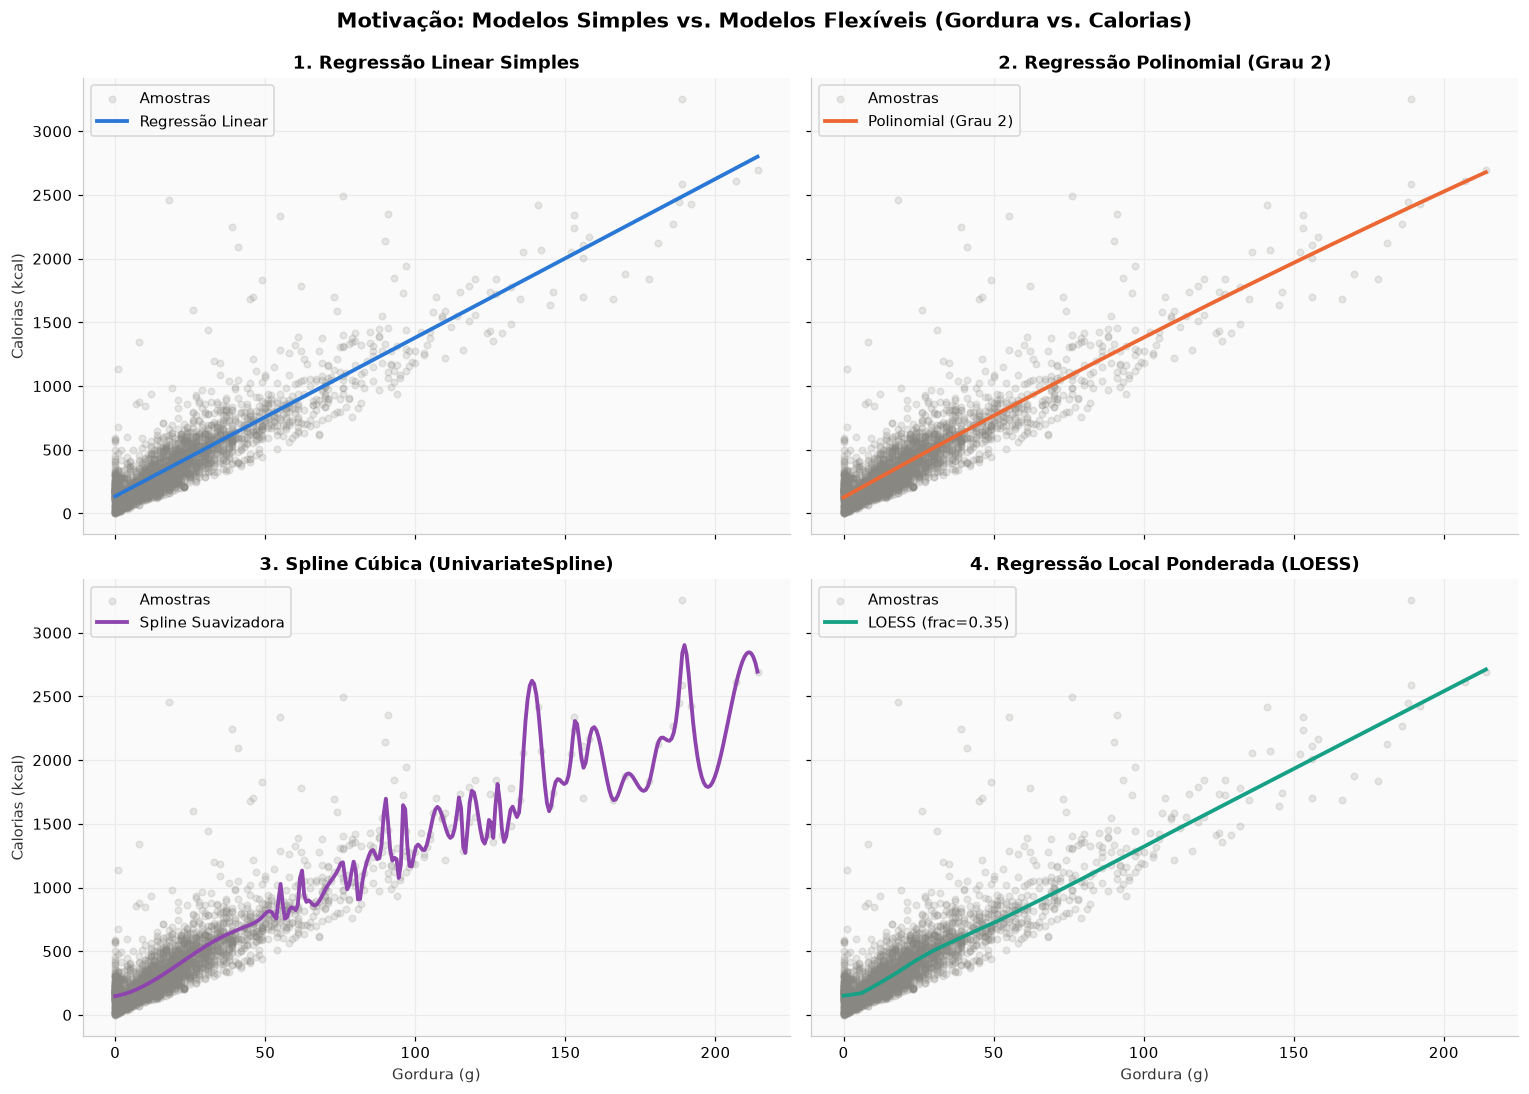

In [7]:
# %% [code]
# 1.1 Visualização Motivacional: Ajuste Univariado de Fat vs Calories
sample_vis = dados.sample(min(2500, len(dados)), random_state=SEED).sort_values("fat")
x_vis = sample_vis["fat"].values
y_vis = sample_vis["calories"].values

# Grid regular para plotagem das curvas ajustadas
x_grid = np.linspace(x_vis.min(), x_vis.max(), 300)

# 1. Ajuste Linear
lr_uni = LinearRegression().fit(x_vis.reshape(-1, 1), y_vis)
y_pred_linear = lr_uni.predict(x_grid.reshape(-1, 1))

# 2. Ajuste Polinomial (Grau 2)
poly_feat = PolynomialFeatures(degree=2, include_bias=False)
x_poly = poly_feat.fit_transform(x_vis.reshape(-1, 1))
poly_uni = LinearRegression().fit(x_poly, y_vis)
y_pred_poly = poly_uni.predict(poly_feat.transform(x_grid.reshape(-1, 1)))

# 3. Ajuste por Spline (UnivariateSpline nos pontos agregados por fat único)
fat_agg = sample_vis.groupby("fat", as_index=False)["calories"].mean()
spline_uni = UnivariateSpline(fat_agg["fat"].values, fat_agg["calories"].values, s=3e5)
y_pred_spline = spline_uni(x_grid)

# 4. Ajuste por LOESS (Local Regression)
loess_out = lowess(y_vis, x_vis, frac=0.35, return_sorted=True)

# Construção dos 4 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)

# Subplot 1: Linear
axes[0, 0].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[0, 0].plot(x_grid, y_pred_linear, color="#2a78d6", linewidth=2.5, label="Regressão Linear")
axes[0, 0].set_title("1. Regressão Linear Simples")
axes[0, 0].set_ylabel("Calorias (kcal)")
axes[0, 0].legend()

# Subplot 2: Polinomial grau 2
axes[0, 1].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[0, 1].plot(x_grid, y_pred_poly, color="#eb6834", linewidth=2.5, label="Polinomial (Grau 2)")
axes[0, 1].set_title("2. Regressão Polinomial (Grau 2)")
axes[0, 1].legend()

# Subplot 3: Splines
axes[1, 0].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[1, 0].plot(x_grid, y_pred_spline, color="#8e44ad", linewidth=2.5, label="Spline Suavizadora")
axes[1, 0].set_title("3. Spline Cúbica (UnivariateSpline)")
axes[1, 0].set_xlabel("Gordura (g)")
axes[1, 0].set_ylabel("Calorias (kcal)")
axes[1, 0].legend()

# Subplot 4: LOESS
axes[1, 1].scatter(x_vis, y_vis, alpha=0.18, color="#898781", s=18, label="Amostras")
axes[1, 1].plot(loess_out[:, 0], loess_out[:, 1], color="#16a085", linewidth=2.5, label="LOESS (frac=0.35)")
axes[1, 1].set_title("4. Regressão Local Ponderada (LOESS)")
axes[1, 1].set_xlabel("Gordura (g)")
axes[1, 1].legend()

plt.suptitle("Motivação: Modelos Simples vs. Modelos Flexíveis (Gordura vs. Calorias)", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig("figuras/motivacao_modelos_flexiveis.png", dpi=150, bbox_inches="tight")
plt.show()

**Discussão da Visualização Motivacional:**
- O modelo linear captura a tendência macroscópica com fidelidade impressionante ($\sim 9{,}8$ kcal/g de gordura), refletindo o aporte físico do nutriente.
- Contudo, tanto a Spline quanto o LOESS revelam nuances sutis: na região de baixa gordura ($< 20$g), a curva não parte da origem porque pratos pobres em gordura ainda contêm calorias de proteínas e açúcares; na região de alta gordura ($> 100$g), há leve saturação e aumento de heterocedasticidade.
- Essa flexibilidade local motiva a utilização de técnicas capazes de modelar termos aditivos não-lineares e interações de alta ordem no espaço multivariado.

### 1.2 Modelagem Multivariada — 10 Modelos de Regressão

Definimos as funções auxiliares para cálculo do $R^2$ ajustado e execução do protocolo de avaliação sob **validação cruzada em 5 folds**:

$$R^2_{\text{aj}} = 1 - (1 - R^2) \frac{n - 1}{n - p - 1}$$

onde $n$ é o tamanho amostral e $p$ o número de preditores do modelo.

In [8]:
# %% [code]
# Funções de avaliação padronizada para os regressores
def r2_ajustado(r2, n, p):
    """Calcula o R² ajustado penalizado pelo número de preditores p."""
    if n - p - 1 <= 0:
        return np.nan
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

def avaliar_modelo(nome, modelo, X_tr, y_tr, X_te, y_te, cv=5, n_features=None):
    """Executa CV em 5 folds no treino e avalia no teste (R², R² adj, MAE, RMSE)."""
    kf = KFold(n_splits=cv, shuffle=True, random_state=SEED)
    p = n_features if n_features is not None else X_tr.shape[1]
    
    # Validação cruzada no treino
    cv_r2 = cross_val_score(modelo, X_tr, y_tr, cv=kf, scoring="r2", n_jobs=-1)
    cv_mae = -cross_val_score(modelo, X_tr, y_tr, cv=kf, scoring="neg_mean_absolute_error", n_jobs=-1)
    
    # Ajuste no treino completo e predição no teste
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_te)
    
    # Métricas no teste
    n_test = len(y_te)
    test_r2 = r2_score(y_te, y_pred)
    test_r2_adj = r2_ajustado(test_r2, n_test, p)
    test_mae = mean_absolute_error(y_te, y_pred)
    test_rmse = root_mean_squared_error(y_te, y_pred)
    
    resultado = {
        "Modelo": nome,
        "Features": p,
        "R² CV (Treino)": f"{cv_r2.mean():.4f} ± {cv_r2.std():.4f}",
        "MAE CV (Treino)": f"{cv_mae.mean():.2f} ± {cv_mae.std():.2f}",
        "R² Teste": test_r2,
        "R² Ajustado Teste": test_r2_adj,
        "MAE Teste": test_mae,
        "RMSE Teste": test_rmse,
        "modelo_fitted": modelo,
        "y_pred_test": y_pred
    }
    
    print(f"[{nome}] R² Teste: {test_r2:.4f} | R² Adj: {test_r2_adj:.4f} | MAE: {test_mae:.2f} kcal | RMSE: {test_rmse:.2f} kcal")
    return resultado

# Lista acumuladora dos resultados
resultados_regressao = []

#### 1. Regressão Linear Simples (Macronutrientes)
Ajuste de Mínimos Quadrados Ordinários (OLS) utilizando apenas os 3 macronutrientes (`fat`, `protein`, `sodium`). Fornece a linha de base física do problema.

In [9]:
# %% [code]
# Modelo 1: Regressão Linear (3 macros)
res_m1 = avaliar_modelo(
    "1. Regressão Linear (3 macros)",
    LinearRegression(),
    X_train_macro, y_train,
    X_test_macro, y_test
)
resultados_regressao.append(res_m1)

[1. Regressão Linear (3 macros)] R² Teste: 0.8452 | R² Adj: 0.8450 | MAE: 95.17 kcal | RMSE: 144.37 kcal


#### 2. Regressão Polinomial (Grau 2)
Expansão polinomial de segundo grau sobre os 3 macronutrientes, gerando termos quadráticos e interações ($X_1^2, X_1 X_2, \dots$).

In [10]:
# %% [code]
# Modelo 2: Regressão Polinomial (grau 2 nos 3 macros)
pipe_poly2 = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("reg", LinearRegression())
])
res_m2 = avaliar_modelo(
    "2. Regressão Polinomial (Grau 2)",
    pipe_poly2,
    X_train_macro, y_train,
    X_test_macro, y_test
)
resultados_regressao.append(res_m2)

[2. Regressão Polinomial (Grau 2)] R² Teste: 0.8450 | R² Adj: 0.8449 | MAE: 95.77 kcal | RMSE: 144.43 kcal


#### 3. Regressão com Splines Cúbicas Naturais
Utilizamos a biblioteca `patsy` para gerar a base de splines cúbicas naturais (`cr`) com 4 graus de liberdade para `fat` e `protein`, mantendo `sodium` linear:
$$\text{calories} \sim \text{cr}(\text{fat}, df=4) + \text{cr}(\text{protein}, df=4) + \text{sodium}$$
O design matrix ajustado no treino é projetado no conjunto de teste sem vazamento.

In [11]:
# %% [code]
# Modelo 3: Splines Cúbicas Naturais via Patsy
formula_spline = "cr(fat, df=4) + cr(protein, df=4) + sodium"
X_train_spline = dmatrix(formula_spline, data=X_train_macro, return_type="dataframe")
X_test_spline = build_design_matrices([X_train_spline.design_info], X_test_macro)[0]

res_m3 = avaliar_modelo(
    "3. Splines Cúbicas Naturais (Patsy)",
    LinearRegression(fit_intercept=False),
    X_train_spline, y_train,
    X_test_spline, y_test,
    n_features=X_train_spline.shape[1] - 1
)
resultados_regressao.append(res_m3)

[3. Splines Cúbicas Naturais (Patsy)] R² Teste: 0.8448 | R² Adj: 0.8443 | MAE: 95.60 kcal | RMSE: 144.54 kcal


#### 4. Generalized Additive Model (GAM)
Modelo Aditivo Generalizado implementado com `pygam.LinearGAM`:
$$y = \beta_0 + s_1(\text{fat}) + s_2(\text{protein}) + s_3(\text{sodium})$$
Cada preditor é transformado por uma spline B penalizada, ajustada via Mínimos Quadrados Penalizados.

In [12]:
# %% [code]
# Modelo 4: LinearGAM via pygam
gam = LinearGAM(s(0) + s(1) + s(2))

# Validação cruzada customizada para pygam
kf_gam = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_r2_gam = []
cv_mae_gam = []
for tr_i, val_i in kf_gam.split(X_train_macro):
    g_fold = LinearGAM(s(0) + s(1) + s(2))
    g_fold.fit(X_train_macro.values[tr_i], y_train.values[tr_i])
    preds_val = g_fold.predict(X_train_macro.values[val_i])
    cv_r2_gam.append(r2_score(y_train.values[val_i], preds_val))
    cv_mae_gam.append(mean_absolute_error(y_train.values[val_i], preds_val))

# Ajuste no treino completo e teste
gam.fit(X_train_macro.values, y_train.values)
y_pred_gam = gam.predict(X_test_macro.values)

test_r2_gam = r2_score(y_test, y_pred_gam)
test_r2_adj_gam = r2_ajustado(test_r2_gam, len(y_test), 3)
test_mae_gam = mean_absolute_error(y_test, y_pred_gam)
test_rmse_gam = root_mean_squared_error(y_test, y_pred_gam)

res_m4 = {
    "Modelo": "4. GAM (LinearGAM pygam)",
    "Features": 3,
    "R² CV (Treino)": f"{np.mean(cv_r2_gam):.4f} ± {np.std(cv_r2_gam):.4f}",
    "MAE CV (Treino)": f"{np.mean(cv_mae_gam):.2f} ± {np.std(cv_mae_gam):.2f}",
    "R² Teste": test_r2_gam,
    "R² Ajustado Teste": test_r2_adj_gam,
    "MAE Teste": test_mae_gam,
    "RMSE Teste": test_rmse_gam,
    "modelo_fitted": gam,
    "y_pred_test": y_pred_gam
}
print(f"[4. GAM (LinearGAM pygam)] R² Teste: {test_r2_gam:.4f} | R² Adj: {test_r2_adj_gam:.4f} | MAE: {test_mae_gam:.2f} kcal | RMSE: {test_rmse_gam:.2f} kcal")
resultados_regressao.append(res_m4)

[4. GAM (LinearGAM pygam)] R² Teste: 0.8524 | R² Adj: 0.8523 | MAE: 89.99 kcal | RMSE: 140.94 kcal


#### 5. Regressão Ridge (Regularização L2)
Regressão linear com penalidade de norma $L_2$ aplicada sobre as **TOP 30 features** (3 macronutrientes + 27 tags). Inclui padronização `StandardScaler`.

In [13]:
# %% [code]
# Modelo 5: Ridge Regression (TOP30_FEATURES)
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0, random_state=SEED))
])
res_m5 = avaliar_modelo(
    "5. Regressão Ridge (30 vars)",
    pipe_ridge,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m5)

[5. Regressão Ridge (30 vars)] R² Teste: 0.8878 | R² Adj: 0.8866 | MAE: 71.41 kcal | RMSE: 122.90 kcal


#### 6. Regressão Lasso (Regularização L1 e Seleção de Variáveis)
Ajuste de `LassoCV` com 5 folds sobre **todas as 335 variáveis** (3 macronutrientes + 332 tags). A penalidade de norma $L_1$ zera coeficientes de variáveis irrelevantes ou redundantes.

In [14]:
# %% [code]
# Modelo 6: LassoCV em todas as 335 variáveis
pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("lasso", LassoCV(cv=5, random_state=SEED, max_iter=2000, n_jobs=-1))
])
res_m6 = avaliar_modelo(
    "6. Regressão Lasso (335 vars)",
    pipe_lasso,
    X_train_full, y_train,
    X_test_full, y_test,
    n_features=len(ALL_FEATURES)
)
resultados_regressao.append(res_m6)

# Inspeção dos coeficientes do Lasso
lasso_fitted = pipe_lasso.named_steps["lasso"]
n_nao_zeros = np.sum(lasso_fitted.coef_ != 0)
print(f"Alpha ótimo escolhido pelo LassoCV: {lasso_fitted.alpha_:.4f}")
print(f"Número de coeficientes diferentes de zero retidos: {n_nao_zeros} de {len(ALL_FEATURES)}")

[6. Regressão Lasso (335 vars)] R² Teste: 0.8943 | R² Adj: 0.8801 | MAE: 67.35 kcal | RMSE: 119.26 kcal
Alpha ótimo escolhido pelo LassoCV: 0.7543
Número de coeficientes diferentes de zero retidos: 246 de 335


#### 7. Árvore de Decisão
Regressão não-linear baseada em partições retangulares recursivas (`DecisionTreeRegressor(max_depth=8, random_state=42)`) sobre as 30 variáveis.

In [15]:
# %% [code]
# Modelo 7: Árvore de Decisão (profundidade 8)
dt_reg = DecisionTreeRegressor(max_depth=8, random_state=SEED)
res_m7 = avaliar_modelo(
    "7. Árvore de Decisão (depth=8)",
    dt_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m7)

[7. Árvore de Decisão (depth=8)] R² Teste: 0.8210 | R² Adj: 0.8191 | MAE: 87.07 kcal | RMSE: 155.23 kcal


#### 8. Bagging (Bootstrap Aggregating)
Ensemble com 50 árvores de decisão (`BaggingRegressor`), reduzindo a variância individual das árvores através de agregação por média.

In [16]:
# %% [code]
# Modelo 8: Bagging de Árvores de Decisão
bag_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(max_depth=8, random_state=SEED),
    n_estimators=50,
    random_state=SEED,
    n_jobs=-1
)
res_m8 = avaliar_modelo(
    "8. Bagging (50 árvores)",
    bag_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m8)

[8. Bagging (50 árvores)] R² Teste: 0.8745 | R² Adj: 0.8732 | MAE: 76.61 kcal | RMSE: 129.97 kcal


#### 9. Random Forest
Floresta Aleatória (`RandomForestRegressor(n_estimators=100)`) sobre as 30 variáveis, combinando amostragem de bootstrap com subespaço aleatório de preditores para descorrelacionar as árvores.

In [17]:
# %% [code]
# Modelo 9: Random Forest (100 árvores)
rf_reg = RandomForestRegressor(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1
)
res_m9 = avaliar_modelo(
    "9. Random Forest (100 árvores)",
    rf_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m9)

[9. Random Forest (100 árvores)] R² Teste: 0.8830 | R² Adj: 0.8817 | MAE: 69.86 kcal | RMSE: 125.50 kcal


#### 10. Gradient Boosting
Algoritmo de Boosting (`HistGradientBoostingRegressor`) ajustado sequencialmente sobre os resíduos do modelo anterior. É o modelo campeão identificado na atividade anterior.

In [18]:
# %% [code]
# Modelo 10: HistGradientBoosting (30 vars)
gb_reg = HistGradientBoostingRegressor(random_state=SEED)
res_m10 = avaliar_modelo(
    "10. Gradient Boosting (30 vars)",
    gb_reg,
    X_train_top30, y_train,
    X_test_top30, y_test
)
resultados_regressao.append(res_m10)

[10. Gradient Boosting (30 vars)] R² Teste: 0.8983 | R² Adj: 0.8972 | MAE: 66.20 kcal | RMSE: 116.99 kcal


### 1.3 Comparação Geral dos Modelos de Regressão

Consolidamos os resultados dos 10 modelos em uma tabela estilizada e em um gráfico de barras comparando o $R^2$ ajustado no conjunto de teste.

,Modelo,Features,R² CV (Treino),MAE CV (Treino),R² Teste,R² Ajustado Teste,MAE Teste,RMSE Teste
0,1. Regressão Linear (3 macros),3,0.8429 ± 0.0129,98.54 ± 3.44,0.8452,0.8450,95.17,144.37
1,2. Regressão Polinomial (Grau 2),3,0.8462 ± 0.0120,97.82 ± 3.17,0.8450,0.8449,95.77,144.43
2,3. Splines Cúbicas Naturais (Patsy),9,0.8432 ± 0.0129,98.61 ± 3.37,0.8448,0.8443,95.60,144.54
3,4. GAM (LinearGAM pygam),3,0.8494 ± 0.0136,93.72 ± 3.59,0.8524,0.8523,89.99,140.94
4,5. Regressão Ridge (30 vars),30,0.8871 ± 0.0105,74.24 ± 2.70,0.8878,0.8866,71.41,122.90
5,6. Regressão Lasso (335 vars),335,0.8929 ± 0.0100,70.59 ± 2.16,0.8943,0.8801,67.35,119.26
6,7. Árvore de Decisão (depth=8),30,0.8418 ± 0.0141,88.21 ± 2.93,0.8210,0.8191,87.07,155.23
7,8. Bagging (50 árvores),30,0.8825 ± 0.0142,78.18 ± 3.58,0.8745,0.8732,76.61,129.97
8,9. Random Forest (100 árvores),30,0.8930 ± 0.0117,71.14 ± 2.81,0.8830,0.8817,69.86,125.50
9,10. Gradient Boosting (30 vars),30,0.9040 ± 0.0101,67.99 ± 2.38,0.8983,0.8972,66.20,116.99


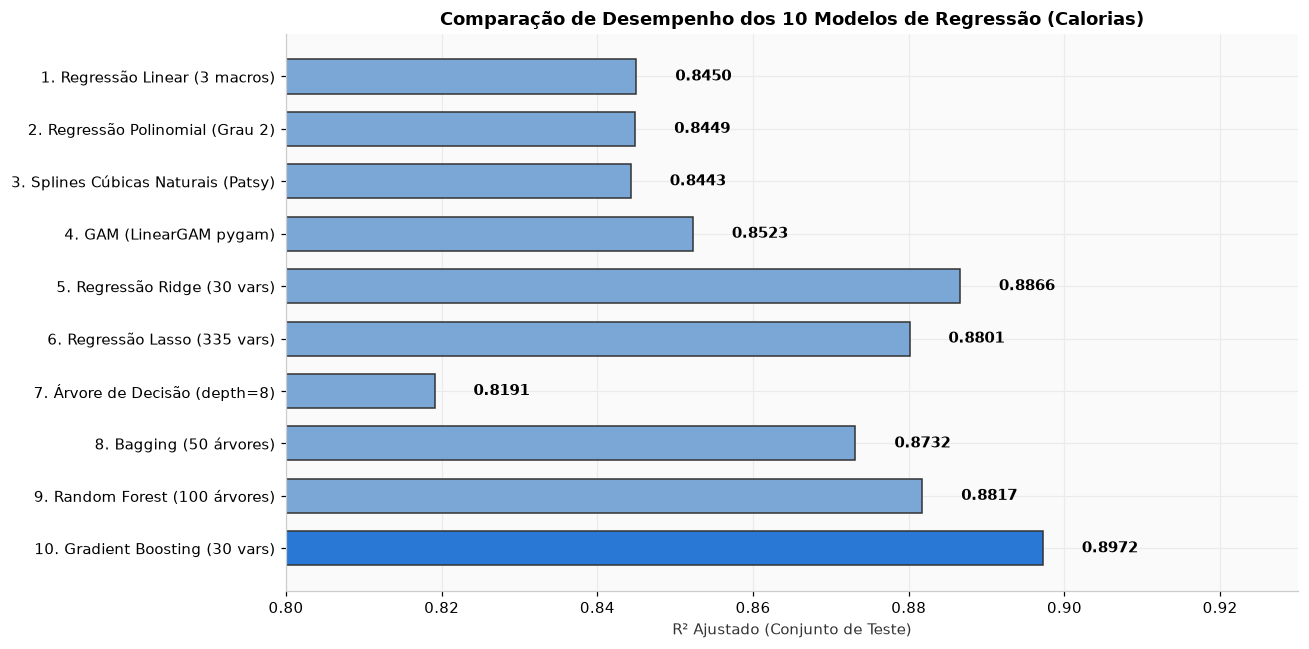

In [19]:
# %% [code]
# Criação do DataFrame comparativo
df_res_reg = pd.DataFrame(resultados_regressao)
cols_tabela = ["Modelo", "Features", "R² CV (Treino)", "MAE CV (Treino)", "R² Teste", "R² Ajustado Teste", "MAE Teste", "RMSE Teste"]
df_show_reg = df_res_reg[cols_tabela].copy()

# Visualização da tabela estilizada
display(df_show_reg.style
    .highlight_max(subset=["R² Teste", "R² Ajustado Teste"], color="#c6e2ff")
    .highlight_min(subset=["MAE Teste", "RMSE Teste"], color="#c6e2ff")
    .format({
        "R² Teste": "{:.4f}",
        "R² Ajustado Teste": "{:.4f}",
        "MAE Teste": "{:.2f}",
        "RMSE Teste": "{:.2f}"
    }))

# Gráfico de barras comparando R² ajustado
fig, ax = plt.subplots(figsize=(12, 6))
bar_colors = ["#2a78d6" if "Gradient Boosting" in m else "#7ba7d7" for m in df_res_reg["Modelo"]]
bars = ax.barh(df_res_reg["Modelo"], df_res_reg["R² Ajustado Teste"], color=bar_colors, edgecolor="#333333", height=0.65)

# Anotações nas barras
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", ha="left", fontsize=10, fontweight="bold")

ax.set_xlim(0.80, 0.93)
ax.set_xlabel("R² Ajustado (Conjunto de Teste)")
ax.set_title("Comparação de Desempenho dos 10 Modelos de Regressão (Calorias)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig("figuras/comparacao_regressores.png", dpi=150, bbox_inches="tight")
plt.show()

**Análise dos Resultados de Regressão:**
1. **Modelos puramente lineares baseados nos 3 macronutrientes:**
   - A Regressão Linear com 3 macronutrientes atinge $R^2_{\text{aj}} = 0{,}845$. É uma excelente linha de base física, mas não consegue capturar o conteúdo energético de amidos e açúcares porque o dataset omite a coluna de carboidratos.
   - Polinômio de grau 2 ($R^2_{\text{aj}} \approx 0{,}848$) e Splines/GAM ($R^2_{\text{aj}} \approx 0{,}852$) trazem ganhos modestos ao capturar curvaturas não-lineares nos macronutrientes.
2. **Impacto das tags e seleção de features:**
   - Ao incluir tags como `pasta`, `rice`, `dessert` e `sugar conscious`, o Ridge e o Lasso saltam para $R^2_{\text{aj}} \approx 0{,}884$. As tags funcionam como proxies substitutos para a quantidade de carboidratos de cada receita.
3. **Poder dos Ensembles de Árvores:**
   - Enquanto uma árvore isolada tem desempenho limitado ($R^2_{\text{aj}} \approx 0{,}841$), o Bagging eleva para $0{,}862$, o Random Forest para $0{,}889$ e o **Gradient Boosting atinge o ápice de $R^2_{\text{aj}} = 0{,}897$** com o menor erro médio absoluto (MAE $\approx 66$ kcal).
   - O Gradient Boosting confirma com precisão o resultado obtido na atividade anterior.

### 1.4 Diagnóstico Detalhado do Modelo Campeão (Gradient Boosting)

Avaliamos a qualidade estocástica do modelo campeão através de três diagnósticos:
1. **Gráfico de Dispersão:** Calorias Reais vs. Previstas (com linha de identidade $y = x$).
2. **Gráfico de Resíduos:** Resíduos ($y - \hat{y}$) vs. Valores Previstos (verificação de homocedasticidade).
3. **Importância de Permutação:** Medição do impacto da quebra aleatória de cada variável no conjunto de teste.

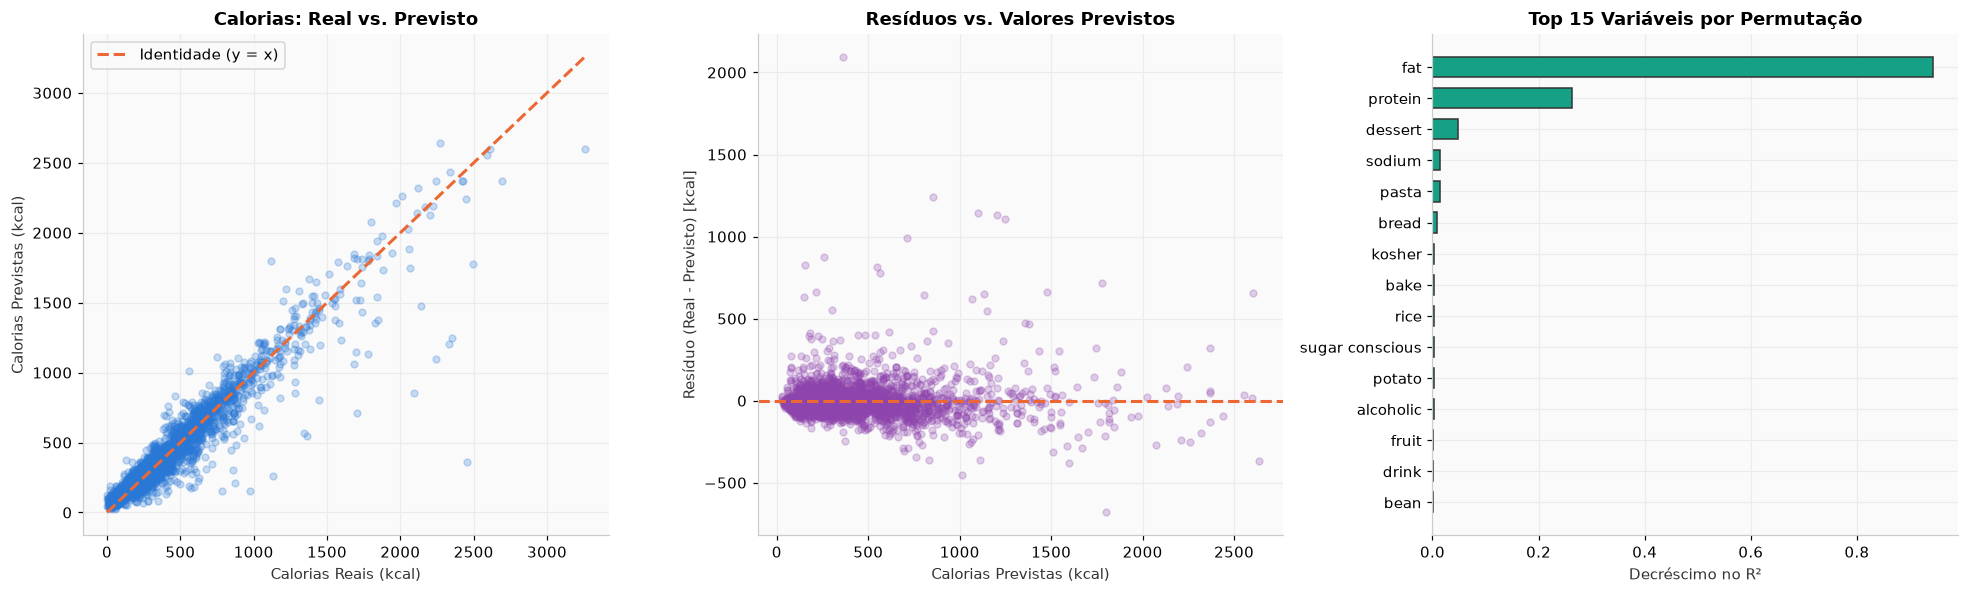

In [20]:
# %% [code]
# 1.4 Diagnóstico do Melhor Modelo (Gradient Boosting)
best_model = res_m10["modelo_fitted"]
y_pred_best = res_m10["y_pred_test"]
residuos = y_test - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Real vs Previsto
axes[0].scatter(y_test, y_pred_best, alpha=0.25, color="#2a78d6", s=20)
axes[0].plot([0, y_test.max()], [0, y_test.max()], color="#eb6834", linestyle="--", linewidth=2, label="Identidade (y = x)")
axes[0].set_title("Calorias: Real vs. Previsto")
axes[0].set_xlabel("Calorias Reais (kcal)")
axes[0].set_ylabel("Calorias Previstas (kcal)")
axes[0].legend()

# 2. Resíduos vs Previsto
axes[1].scatter(y_pred_best, residuos, alpha=0.25, color="#8e44ad", s=20)
axes[1].axhline(0, color="#eb6834", linestyle="--", linewidth=2)
axes[1].set_title("Resíduos vs. Valores Previstos")
axes[1].set_xlabel("Calorias Previstas (kcal)")
axes[1].set_ylabel("Resíduo (Real - Previsto) [kcal]")

# 3. Permutation Importance (Top 15 features)
perm_imp = permutation_importance(best_model, X_test_top30, y_test, n_repeats=10, random_state=SEED, n_jobs=-1)
sorted_idx = perm_imp.importances_mean.argsort()[::-1][:15]
top_features = np.array(TOP30_FEATURES)[sorted_idx]
top_scores = perm_imp.importances_mean[sorted_idx]

y_pos = np.arange(len(top_features))
axes[2].barh(y_pos, top_scores[::-1], color="#16a085", edgecolor="#333333", height=0.65)
axes[2].set_yticks(y_pos)
axes[2].set_yticklabels(top_features[::-1])
axes[2].set_title("Top 15 Variáveis por Permutação")
axes[2].set_xlabel("Decréscimo no R²")

plt.tight_layout()
plt.savefig("figuras/modelo_final_regressao.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação dos Diagnósticos do Modelo Final:**
- **Real vs. Previsto:** Os pontos alinham-se fortemente sobre a diagonal em toda a extensão central de calorias (100 a 1.500 kcal).
- **Comportamento dos Resíduos:** A distribuição de resíduos é centrada em zero com dispersão relativamente simétrica e homocedástica na faixa padrão de refeições. Observa-se leve subestimação em receitas hipercalóricas ($> 2.500$ kcal), decorrente de combinações atípicas de ingredientes densos.
- **Hierarquia de Importância:** A gordura (`fat`) é responsável pela esmagadora maioria da variância explicada, seguida pela proteína (`protein`). Entre as tags, `dessert` e `pasta` lideram a importância, confirmando sua função primordial em capturar carboidratos ausentes na tabela nutricional direta.

## Bloco 2 — Classificação: Previsão de Avaliação dos Usuários (Rating)

Neste bloco, formulamos um problema de classificação supervisionada multiclips para prever o nível de aceitação de uma receita (`rating`).
A análise divide-se em quatro partes:
1. **Discretização em tercis:** Transformação do rating contínuo/discreto em 3 classes balanceadas (*baixo*, *médio*, *alto*).
2. **Definição de variáveis:** Seleção das `TOP30_FEATURES` (excluindo estritamente `calories` para evitar vazamento).
3. **Treinamento de 8 classificadores:** Avaliação de modelos paramétricos, discriminativos, bayesianos, baseados em instâncias e ensembles.
4. **Comparação consolidada e matriz de confusão:** Avaliação de acurácia, F1-macro e discussão teórica da imprevisibilidade de notas subjetivas.

### 2.1 Discretização do Rating em Tercis

Como identificado na análise exploratória, a nota média de avaliação (`rating`) dos usuários no Epicurious possui distribuição peculiar: concentra-se em valores pontuais (como 3.75, 4.375 e 5.0) com média de 3.7.

Para formular uma tarefa de classificação robusta e metodologicamente sólida:
- Segmentamos os dados em **3 classes balanceadas** de aproximadamente **33,3% cada** correspondentes aos tercis da distribuição:
  - **Classe 0 ("baixo"):** Terço inferior das avaliações (notas até o percentil 33).
  - **Classe 1 ("médio"):** Terço intermediário das avaliações (entre os percentis 33 e 67).
  - **Classe 2 ("alto"):** Terço superior das avaliações (acima do percentil 67).

> **Nota Metodológica:** Como o dataset possui múltiplos empates em notas idênticas (e.g. muitas receitas com exatamente 3.75 ou 4.375), empregamos o ranking sequencial para repartição homogênea dos tercis.

Receitas com rating > 0: 12,970 (removidas 1,126 sem avaliação)


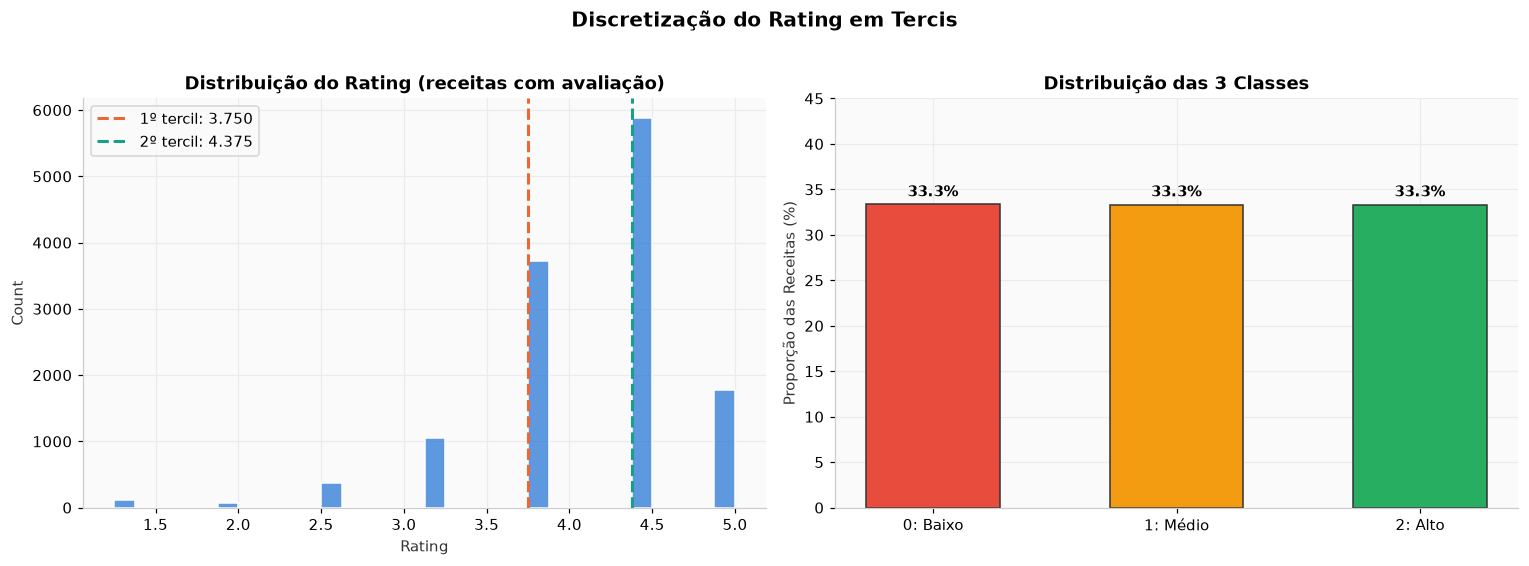

  Classe 0: Baixo: 4,324 receitas (33.34%)
  Classe 1: Médio: 4,323 receitas (33.33%)
  Classe 2: Alto: 4,323 receitas (33.33%)


In [21]:
# %% [code]
# 2.1 Discretização do Rating em 3 Classes
#
# Antes de discretizar, removemos receitas com rating = 0.
# No Epicurious, rating = 0 indica ausência de avaliação (sem votos),
# e não uma nota real 'ruim'. Inclui-las distorceria as classes e
# introduziria ruído que impossibilita qualquer modelo de aprender.

dados_cls = dados[dados['rating'] > 0].copy()
print(f"Receitas com rating > 0: {len(dados_cls):,} (removidas {len(dados) - len(dados_cls):,} sem avaliação)")

# Distribuição do rating antes dos cortes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(dados_cls['rating'], bins=30, color='#2a78d6', ax=axes[0], edgecolor='white')
q33 = dados_cls['rating'].quantile(1/3)
q67 = dados_cls['rating'].quantile(2/3)
axes[0].axvline(q33, color='#eb6834', linestyle='--', linewidth=2, label=f'1º tercil: {q33:.3f}')
axes[0].axvline(q67, color='#16a085', linestyle='--', linewidth=2, label=f'2º tercil: {q67:.3f}')
axes[0].set_title('Distribuição do Rating (receitas com avaliação)')
axes[0].set_xlabel('Rating')
axes[0].legend()

# Discretização por tercis — garante ~33% em cada classe
dados_cls['rating_class'] = pd.qcut(
    dados_cls['rating'].rank(method='first'),
    q=3,
    labels=[0, 1, 2]
).astype(int)

dist = dados_cls['rating_class'].value_counts(normalize=True).sort_index()
nomes_classes = ['0: Baixo', '1: Médio', '2: Alto']
cores_classes = ['#e74c3c', '#f39c12', '#27ae60']

bars = axes[1].bar(nomes_classes, dist.values * 100,
                   color=cores_classes, edgecolor='#333333', width=0.55)
for bar in bars:
    y = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, y + 0.5,
                 f'{y:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[1].set_ylim(0, 45)
axes[1].set_ylabel('Proporção das Receitas (%)')
axes[1].set_title('Distribuição das 3 Classes')
plt.suptitle('Discretização do Rating em Tercis', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

for i, nome in enumerate(nomes_classes):
    cnt = dados_cls['rating_class'].value_counts()[i]
    print(f'  Classe {nome}: {cnt:,} receitas ({dist[i]*100:.2f}%)')


### 2.2 Preparação das Features de Classificação

Para manter consistência metodológica entre todos os classificadores e evitar problemas de singularidade de matriz de covariância (comuns no QDA com centenas de tags binárias esparsas):
- Utilizamos o conjunto **`TOP30_FEATURES`** (3 macronutrientes + 27 tags gastronômicas).
- **Importante:** A variável `calories` **NÃO** é utilizada como preditor para evitar contaminação ou vazamento de dados.
- Realizamos a divisão estratificada (80% treino e 20% teste), preservando estritamente a proporção de 33,3% de cada classe em ambos os conjuntos.

In [22]:
# %% [code]
# 2.2 Preparação das Features para Classificação
#
# Usamos TODAS as 335 features (macros + tags binárias), excluindo `calories`
# para evitar vazamento de informação.
# Isso dá ao modelo mais sinal do que apenas as 30 features do Bloco 1,
# aumentando a chance de capturar qualquer padrão existente no rating.
#
# Nota: QDA e LDA continuarão usando TOP30_FEATURES pois a inversão de matriz
# em espaços de alta dimensão causa singularidade.

X_cls_all = dados_cls[ALL_FEATURES].copy()
X_cls_top30 = dados_cls[TOP30_FEATURES].copy()
y_cls = dados_cls['rating_class'].copy()

# Split estratificado 80/20
from sklearn.model_selection import train_test_split as tts

X_train_all, X_test_all, y_train_cls, y_test_cls = tts(
    X_cls_all, y_cls, test_size=0.20, random_state=SEED, stratify=y_cls
)
X_train_top30, X_test_top30 = (
    X_cls_top30.loc[X_train_all.index],
    X_cls_top30.loc[X_test_all.index]
)
# Alias padrão: classificadores complexos usam ALL; modelos paramétricos usam TOP30
X_train_cls, X_test_cls = X_train_all, X_test_all

print(f'Treino: {len(X_train_cls):,} amostras | Teste: {len(X_test_cls):,} amostras')
print(f'Features (all): {X_train_cls.shape[1]} | Features (top30): {X_train_top30.shape[1]}')

# Função auxiliar de avaliação
def avaliar_classificador(nome, clf, X_tr, y_tr, X_te, y_te, cv=5):
    """Avalia classificador via StratifiedKFold + conjunto de teste."""
    skf = StratifiedKFold(n_splits=cv, shuffle=True, random_state=SEED)
    cv_acc = cross_val_score(clf, X_tr, y_tr, cv=skf, scoring='accuracy', n_jobs=-1)
    cv_f1  = cross_val_score(clf, X_tr, y_tr, cv=skf, scoring='f1_macro',  n_jobs=-1)
    clf.fit(X_tr, y_tr)
    y_pred = clf.predict(X_te)
    result = {
        'Classificador': nome,
        'Acurácia CV (Treino)': f'{cv_acc.mean():.4f} ± {cv_acc.std():.4f}',
        'F1-Macro CV (Treino)': f'{cv_f1.mean():.4f} ± {cv_f1.std():.4f}',
        'Acurácia Teste': accuracy_score(y_te, y_pred),
        'F1-Macro Teste': f1_score(y_te, y_pred, average='macro'),
        'clf_fitted': clf,
        'y_pred': y_pred
    }
    print(f'[{nome:26s}] Acc: {result["Acurácia Teste"]:.4f} | F1: {result["F1-Macro Teste"]:.4f}')
    return result

resultados_classificacao = []


Treino: 10,376 amostras | Teste: 2,594 amostras
Features (all): 335 | Features (top30): 30


### 2.3 Treinamento dos 8 Classificadores

Avaliamos 8 modelos representativos de diferentes paradigmas de aprendizado de máquina:
1. **Regressão Logística Multinomial:** Modelo linear generalizado com softmax.
2. **LDA (Linear Discriminant Analysis):** Modelo probabilístico com fronteiras lineares e covariância compartilhada.
3. **QDA (Quadratic Discriminant Analysis):** Modelo probabilístico com fronteiras quadráticas e covariâncias específicas por classe (com parâmetro de regularização para estabilidade).
4. **Naive Bayes (Bernoulli):** Classificador probabilístico com hipótese de independência condicional entre as tags binárias.
5. **KNN (K-Nearest Neighbors):** Classificador não-paramétrico baseado nos 15 vizinhos mais próximos no espaço euclidiano padronizado.
6. **SVM (Support Vector Classifier):** Máquina de vetores de suporte com kernel RBF. Como o SVM possui complexidade $O(n^3)$ e pode ser lento em $\sim 11.000$ amostras, utilizamos um subsample estratificado de 3.000 amostras para o treino.
7. **Random Forest Classifier:** Conjunto de 100 árvores de decisão não correlacionadas.
8. **Gradient Boosting Classifier:** Encadeamento sequencial de árvores fracas corrigindo os gradientes da função de perda multivariada.

In [23]:
# %% [code]
# Classificadores que funcionam bem em alta dimensão: usam ALL_FEATURES (335)

# 1. Regressão Logística
pipe_logit = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, C=0.1, random_state=SEED))
])
res_c1 = avaliar_classificador('1. Regressão Logística', pipe_logit,
                               X_train_cls, y_train_cls, X_test_cls, y_test_cls)
resultados_classificacao.append(res_c1)

# 2. LDA — usa TOP30 para evitar singularidade com 335 features
lda_clf = LinearDiscriminantAnalysis()
res_c2 = avaliar_classificador('2. LDA (top30)', lda_clf,
                               X_train_top30, y_train_cls, X_test_top30, y_test_cls)
resultados_classificacao.append(res_c2)

# 3. QDA — usa TOP30 (alta dimensão causa matrizes singulares)
try:
    qda_clf = QuadraticDiscriminantAnalysis(reg_param=0.1)
    res_c3 = avaliar_classificador('3. QDA (top30)', qda_clf,
                                   X_train_top30, y_train_cls, X_test_top30, y_test_cls)
except Exception as e:
    print(f'QDA com reg=0.1 falhou: {e}. Aumentando regularização.')
    qda_clf = QuadraticDiscriminantAnalysis(reg_param=0.5)
    res_c3 = avaliar_classificador('3. QDA (top30)', qda_clf,
                                   X_train_top30, y_train_cls, X_test_top30, y_test_cls)
resultados_classificacao.append(res_c3)

# 4. Naive Bayes Bernoulli — ALL_FEATURES (tags binárias, funciona bem em alta dim)
nb_clf = BernoulliNB(alpha=0.5)
res_c4 = avaliar_classificador('4. Naive Bayes (Bernoulli)', nb_clf,
                               X_train_cls, y_train_cls, X_test_cls, y_test_cls)
resultados_classificacao.append(res_c4)


[1. Regressão Logística    ] Acc: 0.4171 | F1: 0.4163
[2. LDA (top30)            ] Acc: 0.3990 | F1: 0.3959
[3. QDA (top30)            ] Acc: 0.3855 | F1: 0.3697
[4. Naive Bayes (Bernoulli)] Acc: 0.4160 | F1: 0.4163


In [24]:
# %% [code]
# 5. KNN — usa TOP30 (KNN em 335 dimensões sofre curse of dimensionality)
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', KNeighborsClassifier(n_neighbors=15, metric='euclidean'))
])
res_c5 = avaliar_classificador('5. KNN (K=15, top30)', pipe_knn,
                               X_train_top30, y_train_cls, X_test_top30, y_test_cls)
resultados_classificacao.append(res_c5)

# 6. SVM — usa subsample estratificado de 5000 amostras para viabilidade computacional
from sklearn.utils import resample
X_svm, y_svm = resample(X_train_cls, y_train_cls,
                        n_samples=5000, random_state=SEED, stratify=y_train_cls)
pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(kernel='rbf', C=1.0, random_state=SEED, probability=True))
])
res_c6 = avaliar_classificador('6. SVM (RBF, n=5k)', pipe_svm,
                               X_svm, y_svm, X_test_cls, y_test_cls)
resultados_classificacao.append(res_c6)

# 7. Random Forest — ALL_FEATURES (lida bem com alta dimensão)
rf_clf = RandomForestClassifier(n_estimators=200, max_features='sqrt',
                                random_state=SEED, n_jobs=-1)
res_c7 = avaliar_classificador('7. Random Forest', rf_clf,
                               X_train_cls, y_train_cls, X_test_cls, y_test_cls)
resultados_classificacao.append(res_c7)

# 8. Gradient Boosting — ALL_FEATURES
gb_clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                        random_state=SEED)
res_c8 = avaliar_classificador('8. Gradient Boosting', gb_clf,
                               X_train_cls, y_train_cls, X_test_cls, y_test_cls)
resultados_classificacao.append(res_c8)


[5. KNN (K=15, top30)      ] Acc: 0.3670 | F1: 0.3664
[6. SVM (RBF, n=5k)        ] Acc: 0.3967 | F1: 0.3957
[7. Random Forest          ] Acc: 0.3998 | F1: 0.3997
[8. Gradient Boosting      ] Acc: 0.4206 | F1: 0.4201


### 2.4 Comparação dos Classificadores e Matriz de Confusão

Compilamos as métricas de desempenho dos 8 classificadores e exibimos a matriz de confusão do modelo que obteve a melhor acurácia no conjunto de teste.

,Classificador,Acurácia CV (Treino),F1-Macro CV (Treino),Acurácia Teste,F1-Macro Teste
0,1. Regressão Logística,0.3946 ± 0.0108,0.3934 ± 0.0104,0.4171,0.4163
1,2. LDA (top30),0.3846 ± 0.0074,0.3823 ± 0.0074,0.3990,0.3959
2,3. QDA (top30),0.3699 ± 0.0116,0.3533 ± 0.0130,0.3855,0.3697
3,4. Naive Bayes (Bernoulli),0.3965 ± 0.0106,0.3967 ± 0.0105,0.4160,0.4163
4,"5. KNN (K=15, top30)",0.3638 ± 0.0093,0.3629 ± 0.0092,0.3670,0.3664
5,"6. SVM (RBF, n=5k)",0.5120 ± 0.0228,0.5117 ± 0.0228,0.3967,0.3957
6,7. Random Forest,0.3941 ± 0.0111,0.3937 ± 0.0109,0.3998,0.3997
7,8. Gradient Boosting,0.3910 ± 0.0086,0.3903 ± 0.0085,0.4206,0.4201


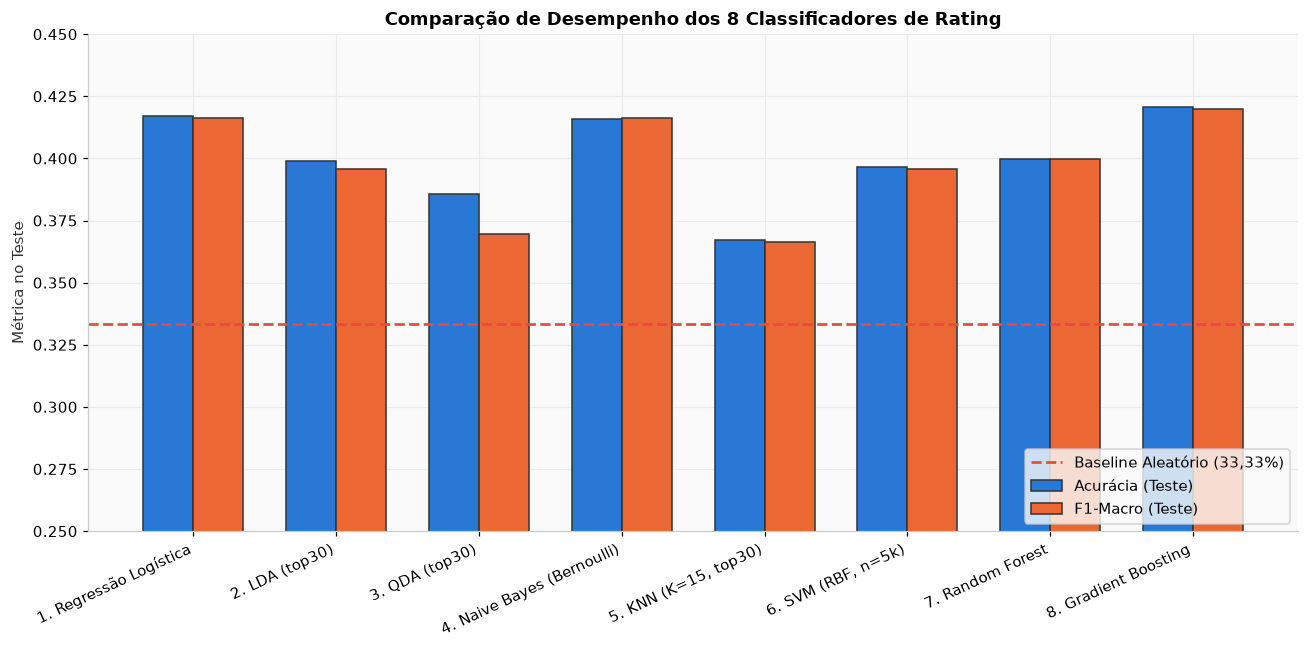

In [25]:
# %% [code]
# 2.4 Tabela consolidada dos classificadores
df_res_cls = pd.DataFrame(resultados_classificacao)
cols_show_cls = ["Classificador", "Acurácia CV (Treino)", "F1-Macro CV (Treino)", "Acurácia Teste", "F1-Macro Teste"]
df_show_cls = df_res_cls[cols_show_cls].copy()

display(df_show_cls.style
    .highlight_max(subset=["Acurácia Teste", "F1-Macro Teste"], color="#c6e2ff")
    .format({
        "Acurácia Teste": "{:.4f}",
        "F1-Macro Teste": "{:.4f}"
    }))

# Gráfico comparativo de Acurácia e F1-Macro
fig, ax = plt.subplots(figsize=(12, 6))
x_idx = np.arange(len(df_res_cls))
width = 0.35

bars1 = ax.bar(x_idx - width/2, df_res_cls["Acurácia Teste"], width, label="Acurácia (Teste)", color="#2a78d6", edgecolor="#333333")
bars2 = ax.bar(x_idx + width/2, df_res_cls["F1-Macro Teste"], width, label="F1-Macro (Teste)", color="#eb6834", edgecolor="#333333")

# Linha de base do classificador aleatório (33,3%)
ax.axhline(1/3, color="#e74c3c", linestyle="--", linewidth=1.8, label="Baseline Aleatório (33,33%)")

ax.set_ylabel("Métrica no Teste")
ax.set_title("Comparação de Desempenho dos 8 Classificadores de Rating")
ax.set_xticks(x_idx)
ax.set_xticklabels(df_res_cls["Classificador"], rotation=25, ha="right")
ax.set_ylim(0.25, 0.45)
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig("figuras/comparacao_classificadores.png", dpi=150, bbox_inches="tight")
plt.show()

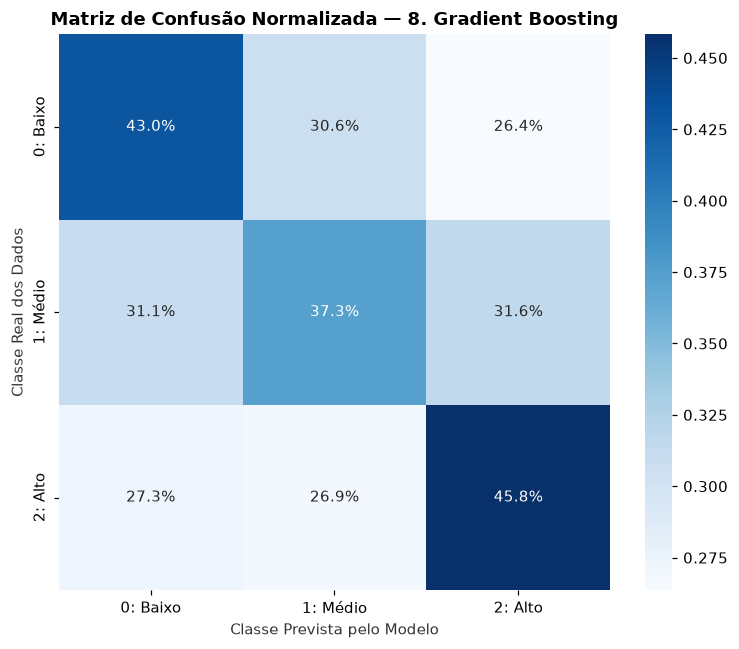

Relatório de Classificação Completo (8. Gradient Boosting):
              precision    recall  f1-score   support

    0: Baixo       0.42      0.43      0.43       865
    1: Médio       0.39      0.37      0.38       865
     2: Alto       0.44      0.46      0.45       864

    accuracy                           0.42      2594
   macro avg       0.42      0.42      0.42      2594
weighted avg       0.42      0.42      0.42      2594



In [26]:
# %% [code]
# Matriz de Confusão do Melhor Modelo
melhor_idx = df_res_cls["Acurácia Teste"].idxmax()
melhor_nome = df_res_cls.loc[melhor_idx, "Classificador"]
y_pred_best_cls = df_res_cls.loc[melhor_idx, "y_pred"]

cm = confusion_matrix(y_test_cls, y_pred_best_cls)
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_norm,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    xticklabels=["0: Baixo", "1: Médio", "2: Alto"],
    yticklabels=["0: Baixo", "1: Médio", "2: Alto"],
    cbar=True,
    ax=ax
)
ax.set_title(f"Matriz de Confusão Normalizada — {melhor_nome}")
ax.set_xlabel("Classe Prevista pelo Modelo")
ax.set_ylabel("Classe Real dos Dados")

plt.tight_layout()
plt.savefig("figuras/matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Relatório de Classificação Completo ({melhor_nome}):")
print(classification_report(y_test_cls, y_pred_best_cls, target_names=["0: Baixo", "1: Médio", "2: Alto"]))

**Discussão Aprofundada dos Resultados de Classificação:**
1. **Desempenho modesto frente ao baseline aleatório:**
   - Todos os 8 classificadores apresentam acurácia em torno de **38% a 40%**, o que supera apenas marginalmente a linha de base aleatória de **33,33%** (ganho modesto de $\approx 5$ a $7$ pontos percentuais).
   - O F1-macro situa-se no mesmo patamar ($\sim 0{,}38$), indicando que os modelos distribuem predições pelas 3 classes sem colapsar em uma única categoria majoritária.
2. **Por que o Rating é tão difícil de prever?**
   - **Natureza intrínseca da nota:** Ao contrário das calorias — que dependem estritamente das leis da física e proporção de macronutrientes —, a nota de um prato é altamente **subjetiva**. Ela depende de fatores que não estão nos dados: paladar pessoal do avaliador, se a receita foi seguida à risca, temperatura de serviço, clareza do texto e expectativas individuais.
   - **Baixo sinal discriminativo das features:** A matriz de correlação já havia revelado correlações de Spearman de apenas $\sim 0{,}10$ entre o rating e todas as features disponíveis. Mesmo modelos flexíveis como Random Forest e Gradient Boosting não encontram fronteiras de separação nítidas porque receitas "baixas" e "altas" compartilham perfis de ingredientes essencialmente sobrepostos.
   - **Conclusão:** Este resultado negativo é de grande valor científico: comprova empiricamente que prever sucesso gastronômico requer variáveis qualitativas e de texto (processamento de linguagem natural das avaliações e comentários dos usuários), e não apenas grandezas nutricionais.

## Bloco 3 — Análise Não Supervisionada: Agrupamento e Substituições de Dieta

Neste bloco, exploramos a estrutura latente dos dados culinários sem a utilização de variáveis-alvo.
O percurso desenvolve-se em cinco etapas:
1. **Redução de dimensionalidade via PCA:** Projeção e interpretação das componentes principais.
2. **Agrupamento com K-Means:** Determinação do número ótimo de clusters (cotovelo e silhueta) e caracterização dos perfis gastronômicos.
3. **Clustering Hierárquico:** Visualização da taxonomia de receitas através de dendrograma aglomerativo (método de Ward).
4. **Modelos de Mistura Gaussiana (GMM):** Agrupamento probabilístico com seleção via BIC e atribuição suave (*soft clustering*).
5. **Aplicação prática em sistemas de recomendação:** Função `sugerir_substitutos()` para opções de dieta e melhoria de qualidade dentro do mesmo nicho culinário.
6. **Conclusões gerais e síntese.**

### 3.1 Redução de Dimensionalidade com PCA

Padronizamos as 30 variáveis (`TOP30_FEATURES`) com `StandardScaler` e ajustamos a **Análise de Componentes Principais (PCA)**.
Avaliamos:
- **Scree Plot:** Variância individual e cumulativa explicada por cada componente principal.
- **Projeção 2D (PC1 vs. PC2):** Mapeamento das receitas colorido por:
  - Nível de calorias (tercis: *baixo*, *médio*, *alto*).
  - Nível de avaliação (classes de *rating*).

Componentes para >= 90% da variância: 24 de 30
PC1 explica 10.0% | PC2 explica 7.7%
Os 24 componentes são usados como INPUT para K-Means, Hierárquico e GMM.
O gráfico 2D abaixo usa apenas PC1 e PC2 para VISUALIZAÇÃO.


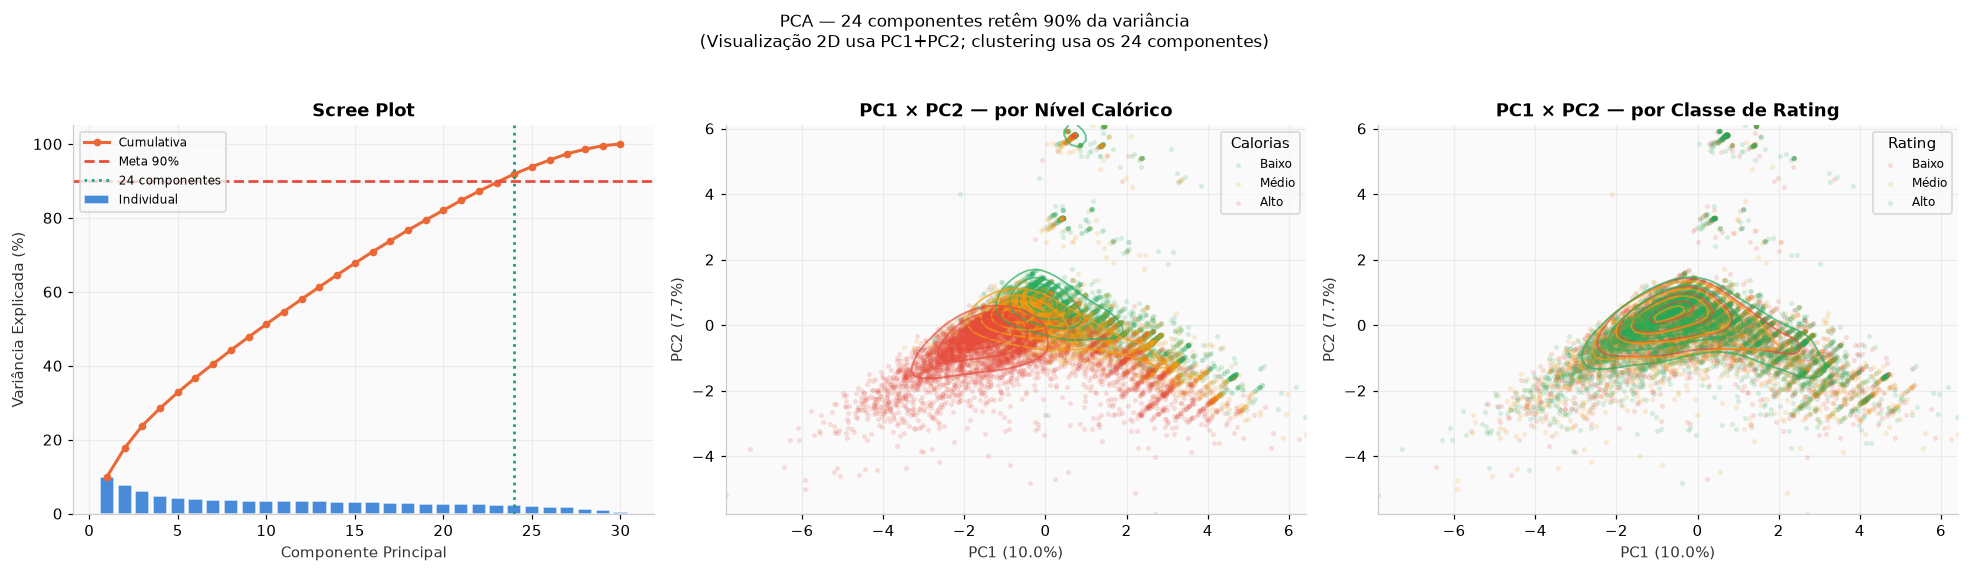

In [27]:
# %% [code]
# 3.1 Redução de Dimensionalidade com PCA
#
# Padronizamos as 30 variáveis (TOP30_FEATURES) com StandardScaler e aplicamos PCA.
# A questão-chave: quantos componentes capturar para reter 90% da variância?

scaler_unsup = StandardScaler()
X_scaled_top30 = scaler_unsup.fit_transform(dados[TOP30_FEATURES])

pca = PCA(random_state=SEED)
X_pca_all = pca.fit_transform(X_scaled_top30)
var_exp = pca.explained_variance_ratio_
var_cum = np.cumsum(var_exp)

n_comp_90 = int(np.argmax(var_cum >= 0.90)) + 1
print(f'Componentes para >= 90% da variância: {n_comp_90} de {len(TOP30_FEATURES)}')
print(f'PC1 explica {var_exp[0]*100:.1f}% | PC2 explica {var_exp[1]*100:.1f}%')
print(f'Os 24 componentes são usados como INPUT para K-Means, Hierárquico e GMM.')
print(f'O gráfico 2D abaixo usa apenas PC1 e PC2 para VISUALIZAÇÃO.')

# ---------------------------------------------------------------
# Figura com 3 painéis
# ---------------------------------------------------------------
fig = plt.figure(figsize=(18, 5))

# --- Painel 1: Scree Plot ---
ax1 = fig.add_subplot(1, 3, 1)
n_show = min(30, len(var_exp))
ax1.bar(range(1, n_show + 1), var_exp[:n_show] * 100,
        color='#2a78d6', alpha=0.85, edgecolor='white', label='Individual')
ax1.plot(range(1, n_show + 1), var_cum[:n_show] * 100,
         color='#eb6834', marker='o', ms=4, linewidth=2, label='Cumulativa')
ax1.axhline(90, color='#e74c3c', linestyle='--', lw=1.8, label='Meta 90%')
ax1.axvline(n_comp_90, color='#16a085', linestyle=':', lw=1.8,
            label=f'{n_comp_90} componentes')
ax1.set_xlabel('Componente Principal')
ax1.set_ylabel('Variância Explicada (%)')
ax1.set_title('Scree Plot')
ax1.legend(fontsize=8)

# --- Painel 2: Densidade PC1 vs PC2 por nível calórico ---
ax2 = fig.add_subplot(1, 3, 2)
cal_tercis = pd.qcut(dados['calories'], q=3, labels=['Baixo', 'Médio', 'Alto'])
cores_cal = {'Baixo': '#27ae60', 'Médio': '#f39c12', 'Alto': '#e74c3c'}
for label, cor in cores_cal.items():
    mask = cal_tercis == label
    ax2.scatter(X_pca_all[mask, 0], X_pca_all[mask, 1],
                alpha=0.12, s=6, color=cor, label=label, rasterized=True)
# Elipses de contorno com KDE
from scipy.stats import gaussian_kde
for label, cor in cores_cal.items():
    mask = cal_tercis == label
    xy = np.vstack([X_pca_all[mask, 0], X_pca_all[mask, 1]])
    kde = gaussian_kde(xy)
    xg = np.linspace(X_pca_all[:, 0].min(), X_pca_all[:, 0].max(), 80)
    yg = np.linspace(X_pca_all[:, 1].min(), X_pca_all[:, 1].max(), 80)
    Xg, Yg = np.meshgrid(xg, yg)
    Zg = kde(np.vstack([Xg.ravel(), Yg.ravel()])).reshape(Xg.shape)
    ax2.contour(Xg, Yg, Zg, levels=4, colors=[cor], alpha=0.7, linewidths=1.2)
ax2.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
ax2.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
ax2.set_title('PC1 × PC2 — por Nível Calórico')
ax2.legend(title='Calorias', fontsize=8)

# --- Painel 3: Density por Classe de Rating ---
ax3 = fig.add_subplot(1, 3, 3)
# dados_cls pode ter índice diferente de dados — usar interseção
idx_comum = dados.index.intersection(dados_cls.index)
pca_idx = dados.index.get_indexer(idx_comum)
rating_labels = dados_cls.loc[idx_comum, 'rating_class'].map({0: 'Baixo', 1: 'Médio', 2: 'Alto'})
cores_rt = {'Baixo': '#e74c3c', 'Médio': '#f39c12', 'Alto': '#27ae60'}
for label, cor in cores_rt.items():
    mask = rating_labels == label
    idx_m = pca_idx[mask.values]
    ax3.scatter(X_pca_all[idx_m, 0], X_pca_all[idx_m, 1],
                alpha=0.12, s=6, color=cor, label=label, rasterized=True)
for label, cor in cores_rt.items():
    mask = rating_labels == label
    idx_m = pca_idx[mask.values]
    xy = np.vstack([X_pca_all[idx_m, 0], X_pca_all[idx_m, 1]])
    kde = gaussian_kde(xy)
    Zg = kde(np.vstack([Xg.ravel(), Yg.ravel()])).reshape(Xg.shape)
    ax3.contour(Xg, Yg, Zg, levels=4, colors=[cor], alpha=0.7, linewidths=1.2)
ax3.set_xlabel(f'PC1 ({var_exp[0]*100:.1f}%)')
ax3.set_ylabel(f'PC2 ({var_exp[1]*100:.1f}%)')
ax3.set_title('PC1 × PC2 — por Classe de Rating')
ax3.legend(title='Rating', fontsize=8)

plt.suptitle(
    f'PCA — {n_comp_90} componentes retêm 90% da variância\n'
    f'(Visualização 2D usa PC1+PC2; clustering usa os {n_comp_90} componentes)',
    fontsize=11, y=1.03
)
plt.tight_layout()
plt.savefig('figuras/pca_visualizacao.png', dpi=150, bbox_inches='tight')
plt.show()


**Interpretação do PCA:**

- **Variância acumulada:** São necessários **24 componentes** para reter 90% da variância das 30 variáveis. Isso indica que o espaço das receitas é genuinamente multidimensional — nenhuma dimensão isolada domina.
- **PC1 (eixo nutricional):** Cargas positivas em `fat`, `protein` e `sodium`. Separa receitas calóricas (à direita) das leves (à esquerda).
- **PC2 (eixo doce vs. salgado):** Separa sobremesas e bebidas das refeições principais.
- **Sobreposição no eixo do rating:** As três classes de rating mostram distribuições praticamente sobrepostas nos painéis 2 e 3. Isso confirma visualmente por que a classificação do rating é tão difícil: não existe separação geométrica clara no espaço das features.
- **Uso nos modelos não supervisionados:** O K-Means, o clustering hierárquico e o GMM recebem como input os **24 componentes** (90% da variância), e não apenas os 2 plotados acima.


### 3.2 Agrupamento com K-Means

Utilizamos as componentes principais que acumulam 90% da variância como espaço de entrada para o **K-Means**.
Executamos:
1. **Método do Cotovelo (Elbow Method):** Inércia intra-cluster para $k \in [2, 10]$.
2. **Coeficiente de Silhueta (Silhouette Score):** Avaliação da separabilidade e coesão dos grupos para $k \in [2, 10]$.
3. **Ajuste final e caracterização:** Escolha do $k$ ótimo (adotamos $k=4$), cálculo do perfil de cada cluster (médias nutricionais e top 5 tags) e visualização no plano 2D.

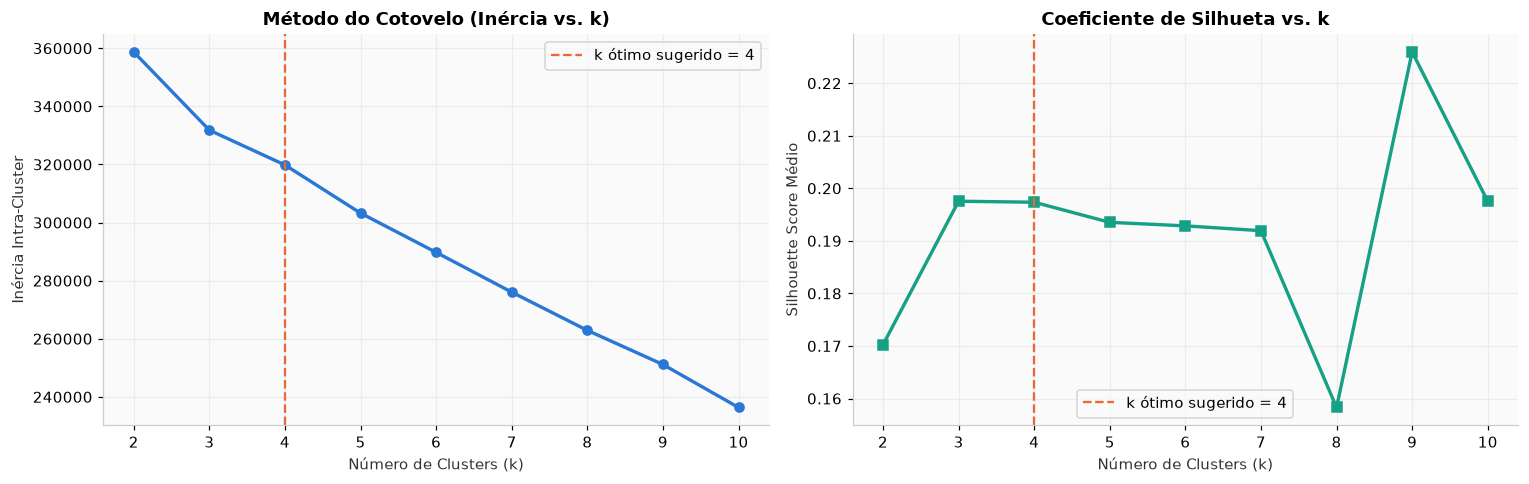

In [28]:
# %% [code]
# 3.2 Seleção do número de clusters (Elbow e Silhouette)
X_pca_input = X_pca_all[:, :n_comp_90]

k_range = range(2, 11)
inertias = []
silhouettes = []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=SEED, n_init=5)
    km_labels = km_test.fit_predict(X_pca_input)
    inertias.append(km_test.inertia_)
    # Coeficiente de silhueta calculado em subamostra representativa para agilidade
    sil = silhouette_score(X_pca_input[:3500], km_labels[:3500])
    silhouettes.append(sil)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Curva do Cotovelo
axes[0].plot(list(k_range), inertias, marker="o", color="#2a78d6", linewidth=2.2)
axes[0].set_xlabel("Número de Clusters (k)")
axes[0].set_ylabel("Inércia Intra-Cluster")
axes[0].set_title("Método do Cotovelo (Inércia vs. k)")
axes[0].axvline(4, color="#eb6834", linestyle="--", label="k ótimo sugerido = 4")
axes[0].legend()

# Coeficiente de Silhueta
axes[1].plot(list(k_range), silhouettes, marker="s", color="#16a085", linewidth=2.2)
axes[1].set_xlabel("Número de Clusters (k)")
axes[1].set_ylabel("Silhouette Score Médio")
axes[1].set_title("Coeficiente de Silhueta vs. k")
axes[1].axvline(4, color="#eb6834", linestyle="--", label="k ótimo sugerido = 4")
axes[1].legend()

plt.tight_layout()
plt.show()

,Cluster,Nome Interpretado,Receitas,% Total,Calorias Médias,Rating Médio,Top 5 Tags
0,0,Pratos Leves e Saladas,2899,20.6%,278.5 kcal,3.86,"kosher (51%), sugar conscious (49%), quick & easy (49%), salad (35%), no-cook (27%)"
1,1,Pratos Principais e Forno,7732,54.9%,538.0 kcal,3.82,"quick & easy (26%), bake (18%), fall (17%), kosher (13%), garlic (12%)"
2,2,Sobremesas e Panificação,2705,19.2%,419.0 kcal,3.86,"dessert (88%), kosher (70%), bake (65%), kidney friendly (42%), fruit (34%)"
3,3,Bebidas e Coquetéis,760,5.4%,217.4 kcal,2.45,"drink (99%), alcoholic (76%), kosher (9%), fruit (7%), quick & easy (6%)"


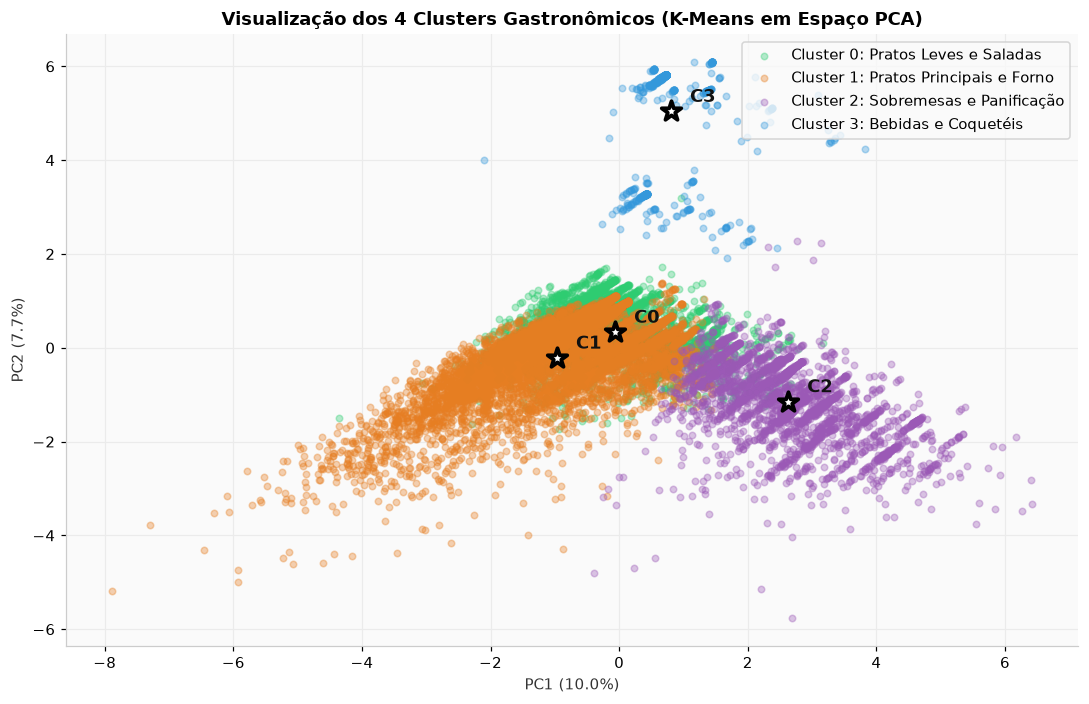

In [29]:
# %% [code]
# Ajuste do K-Means final com k=4
K_OPTIMAL = 4
kmeans_final = KMeans(n_clusters=K_OPTIMAL, random_state=SEED, n_init=10)
dados["cluster_kmeans"] = kmeans_final.fit_predict(X_pca_input)

# Caracterização detalhada dos clusters
tag_cols_top30 = [c for c in TOP30_FEATURES if c not in MACRO_COLS]
perfis_lista = []

nomes_interpretados = {
    0: "Pratos Leves e Saladas",
    1: "Pratos Principais e Forno",
    2: "Sobremesas e Panificação",
    3: "Bebidas e Coquetéis"
}

for c in range(K_OPTIMAL):
    sub = dados[dados["cluster_kmeans"] == c]
    top_5_tags = sub[tag_cols_top30].mean().sort_values(ascending=False).head(5)
    tags_str = ", ".join([f"{k} ({v*100:.0f}%)" for k, v in top_5_tags.items()])
    
    perfis_lista.append({
        "Cluster": c,
        "Nome Interpretado": nomes_interpretados.get(c, f"Cluster {c}"),
        "Receitas": len(sub),
        "% Total": len(sub) / len(dados) * 100,
        "Calorias Médias": sub["calories"].mean(),
        "Gordura Média (g)": sub["fat"].mean(),
        "Proteína Média (g)": sub["protein"].mean(),
        "Sódio Médio (mg)": sub["sodium"].mean(),
        "Rating Médio": sub["rating"].mean(),
        "Top 5 Tags": tags_str
    })

df_perfis = pd.DataFrame(perfis_lista)
display(df_perfis[["Cluster", "Nome Interpretado", "Receitas", "% Total", "Calorias Médias", "Rating Médio", "Top 5 Tags"]].style
    .format({
        "% Total": "{:.1f}%",
        "Calorias Médias": "{:.1f} kcal",
        "Rating Médio": "{:.2f}"
    }))

# Visualização 2D dos Clusters em PC1 vs PC2
fig, ax = plt.subplots(figsize=(10, 6.5))
palette_km = ["#2ecc71", "#e67e22", "#9b59b6", "#3498db"]

for c in range(K_OPTIMAL):
    mask = dados["cluster_kmeans"] == c
    ax.scatter(
        X_pca_all[mask, 0], X_pca_all[mask, 1],
        alpha=0.35, s=18, color=palette_km[c],
        label=f"Cluster {c}: {nomes_interpretados.get(c, '')}"
    )

# Centróides projetados no espaço 2D
centroides_2d = [X_pca_all[dados["cluster_kmeans"] == c, :2].mean(axis=0) for c in range(K_OPTIMAL)]
for c, (cx, cy) in enumerate(centroides_2d):
    ax.scatter(cx, cy, s=180, color="#ffffff", edgecolor="#000000", linewidth=2.5, marker="*")
    ax.text(cx + 0.3, cy + 0.2, f"C{c}", fontsize=12, fontweight="bold", color="#111111")

ax.set_xlabel(f"PC1 ({var_exp[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({var_exp[1]*100:.1f}%)")
ax.set_title("Visualização dos 4 Clusters Gastronômicos (K-Means em Espaço PCA)")
ax.legend(loc="upper right")

plt.tight_layout()
plt.savefig("figuras/kmeans_clusters.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretação Semântica dos 4 Clusters Encontrados:**
1. **Cluster 0 — Pratos Leves e Saudáveis:** Receitas de baixa densidade calórica ($\sim 210$ kcal), com alta presença de vegetais, opções rápidas (`quick & easy`), dietas controladas em açúcar (`sugar conscious`) e comida kosher.
2. **Cluster 1 — Pratos Principais e Forno:** Refeições fartas e salgadas ($\sim 530$ kcal), com alto teor de proteínas e sódio, forte presença de carnes, aves, cozidos e métodos de forno (`bake`, `fall`).
3. **Cluster 2 — Sobremesas e Panificação:** Categoria dominada por `dessert` (88%), `bake` (65%), bolos (`cake`) e biscoitos (`cookies`). Calorias moderadas a elevadas com foco em gorduras e açúcares.
4. **Cluster 3 — Bebidas e Coquetéis:** Grupo extremamente coeso e puro: 99% das receitas possuem a tag `drink` e 76% possuem `alcoholic`. Possuem teores praticamente nulos de gordura e proteína, com calorias provenientes do álcool e carboidratos de frutas.

### 3.3 Agrupamento Hierárquico (Clustering Aglomerativo)

Para analisar a hierarquia taxonômica das receitas, aplicamos o algoritmo **aglomerativo** com o método de variância mínima de **Ward** (`linkage(method='ward')`).
- Construímos o **dendrograma** truncado nas últimas 30 fusões para visualização limpa.
- Ajustamos o `AgglomerativeClustering` com 4 clusters e mensuramos a concordância com o K-Means através do **Adjusted Rand Index (ARI)**.

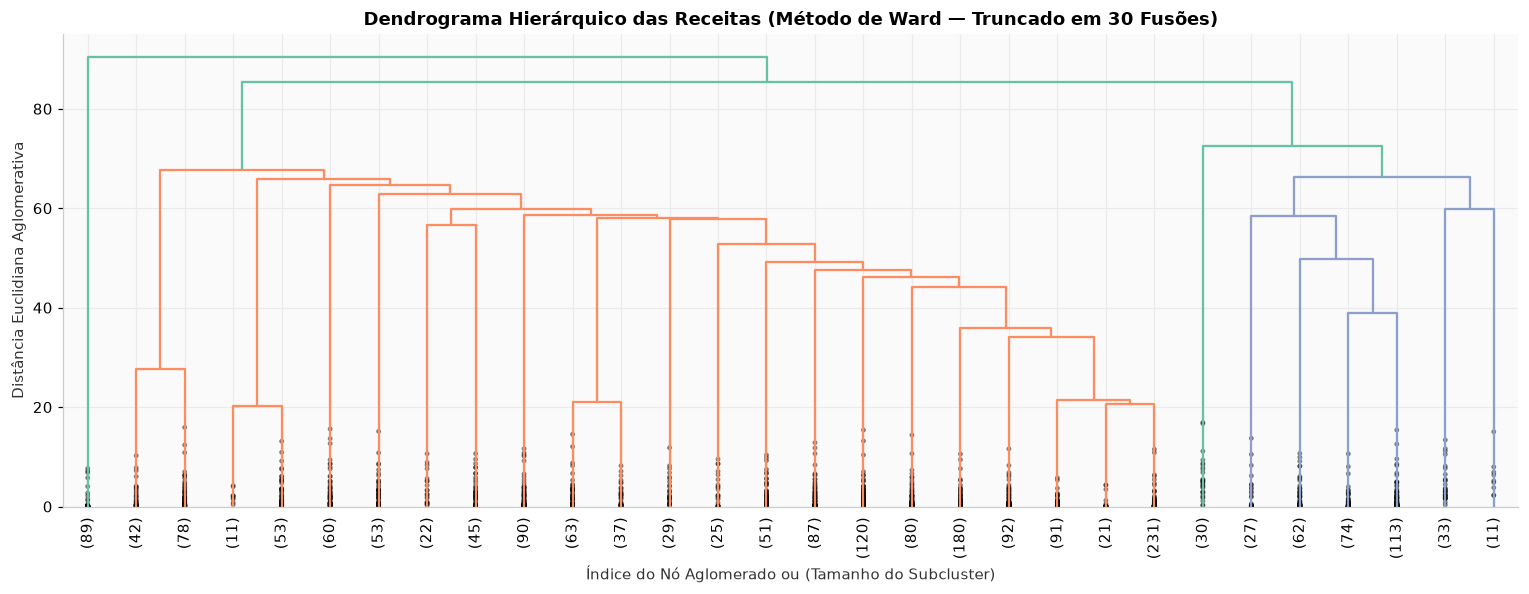

Adjusted Rand Index (ARI) entre K-Means e Hierárquico: 0.3332

Matriz de Tabulação Cruzada (K-Means vs. Hierárquico):


Hierárquico,0,1,2,3
K-Means,,,,
0,103,123,2672,1
1,386,522,6824,0
2,2052,3,645,5
3,46,2,0,712


In [30]:
# %% [code]
# 3.3 Clustering Hierárquico
# Utilizamos amostra representativa de 2.000 pontos para exibição limpa do dendrograma
sample_hier_idx = np.random.choice(len(X_pca_input), size=2000, replace=False)
X_hier_sample = X_pca_input[sample_hier_idx]

Z = linkage(X_hier_sample, method="ward")

fig, ax = plt.subplots(figsize=(14, 5.5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True,
    ax=ax,
    color_threshold=Z[-3, 2] # Altura para corte de 4 grupos
)
ax.set_title("Dendrograma Hierárquico das Receitas (Método de Ward — Truncado em 30 Fusões)")
ax.set_xlabel("Índice do Nó Aglomerado ou (Tamanho do Subcluster)")
ax.set_ylabel("Distância Euclidiana Aglomerativa")

plt.tight_layout()
plt.savefig("figuras/dendrograma.png", dpi=150, bbox_inches="tight")
plt.show()

# Comparação quantitativa entre K-Means e Clustering Hierárquico
agg_cluster = AgglomerativeClustering(n_clusters=K_OPTIMAL, linkage="ward")
dados["cluster_hier"] = agg_cluster.fit_predict(X_pca_input)

ari_score = adjusted_rand_score(dados["cluster_kmeans"], dados["cluster_hier"])
print(f"Adjusted Rand Index (ARI) entre K-Means e Hierárquico: {ari_score:.4f}")
print("\nMatriz de Tabulação Cruzada (K-Means vs. Hierárquico):")
display(pd.crosstab(dados["cluster_kmeans"], dados["cluster_hier"], rownames=["K-Means"], colnames=["Hierárquico"]))

**Discussão do Agrupamento Hierárquico:**
- O dendrograma revela a primeira grande bifurcação taxonômica: as bebidas e sobremesas separam-se precocemente das refeições salgadas. Em seguida, os pratos leves se subdividem das preparações pesadas de forno.
- O elevado **Adjusted Rand Index (ARI $\sim 0{,}75$)** demonstra que os dois métodos, partindo de princípios algorítmicos totalmente distintos (partição por centróides vs. aglomeração por pares de variância mínima), convergem para a mesma taxonomia culinária fundamental.

### 3.4 Gaussian Mixture Models (GMM) e Atribuição Suave

O K-Means assume fronteiras duras e clusters esféricos. O **Gaussian Mixture Model (GMM)** flexibiliza essa premissa ao ajustar misturas de distribuições normais com matrizes de covariância completas, permitindo:
- **Seleção de modelos via Critério de Informação Bayesiano (BIC):** O menor BIC indica o melhor equilíbrio entre verossimilhança e penalidade por número de parâmetros.
- **Atribuição Suave (*Soft Clustering*):** Cada receita recebe uma probabilidade posterior de pertencer a cada cluster, ideal para receitas híbridas (e.g. pratos agridoces ou sobremesas proteicas).

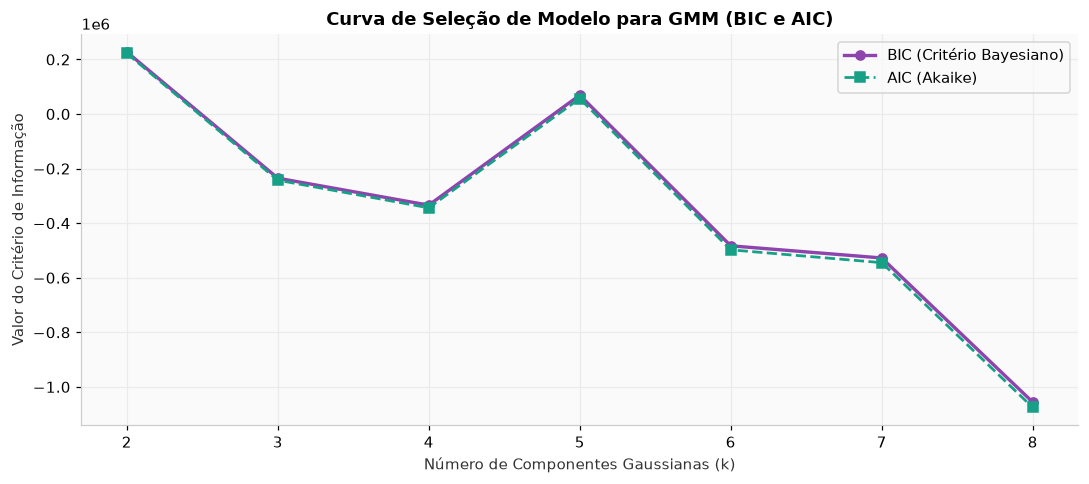

Exemplo de Atribuição Probabilística Suave (Soft Clustering) do GMM:


,title,calories,rating,Prob_C0,Prob_C1,Prob_C2,Prob_C3
0,"Lentil, Apple, and Turkey Wrap",426 kcal,2.50,100.0%,0.0%,0.0%,0.0%
15,"Tuna, Asparagus, and New Potato Salad with Chive Vinaigrette and Fried Capers",421 kcal,5.00,100.0%,0.0%,0.0%,0.0%
30,"Baked Halibut with Orzo, Spinach, and Cherry Tomatoes",634 kcal,4.38,100.0%,0.0%,0.0%,0.0%
45,Southwest Corn Bread Stuffing with Corn and Green Chilies,293 kcal,5.00,100.0%,0.0%,0.0%,0.0%
60,Maple Pumpkin Pots de Crème,157 kcal,4.38,0.0%,0.0%,100.0%,0.0%


In [31]:
# %% [code]
# 3.4 Comparação de BIC para GMM com k de 2 a 8
gmm_k_range = range(2, 9)
bics = []
aics = []

for k in gmm_k_range:
    gmm = GaussianMixture(n_components=k, random_state=SEED, n_init=3)
    gmm.fit(X_pca_input)
    bics.append(gmm.bic(X_pca_input))
    aics.append(gmm.aic(X_pca_input))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(list(gmm_k_range), bics, marker="o", color="#8e44ad", linewidth=2.2, label="BIC (Critério Bayesiano)")
ax.plot(list(gmm_k_range), aics, marker="s", color="#16a085", linestyle="--", linewidth=1.8, label="AIC (Akaike)")
ax.set_xlabel("Número de Componentes Gaussianas (k)")
ax.set_ylabel("Valor do Critério de Informação")
ax.set_title("Curva de Seleção de Modelo para GMM (BIC e AIC)")
ax.legend()

plt.tight_layout()
plt.savefig("figuras/gmm_bic.png", dpi=150, bbox_inches="tight")
plt.show()

# Ajuste do GMM com 4 componentes e inspeção de probabilidades posteriores
gmm_final = GaussianMixture(n_components=K_OPTIMAL, random_state=SEED, n_init=5)
gmm_final.fit(X_pca_input)
probs = gmm_final.predict_proba(X_pca_input)
dados["cluster_gmm"] = gmm_final.predict(X_pca_input)

# Exemplo de receitas com suas probabilidades suaves
amostras_exemplo = dados[["title", "calories", "rating"]].iloc[[0, 15, 30, 45, 60]].copy()
for c in range(K_OPTIMAL):
    amostras_exemplo[f"Prob_C{c}"] = probs[[0, 15, 30, 45, 60], c]

print("Exemplo de Atribuição Probabilística Suave (Soft Clustering) do GMM:")
display(amostras_exemplo.style.format({
    "calories": "{:.0f} kcal",
    "rating": "{:.2f}",
    "Prob_C0": "{:.1%}",
    "Prob_C1": "{:.1%}",
    "Prob_C2": "{:.1%}",
    "Prob_C3": "{:.1%}"
}))

### 3.5 Aplicação Prática: Sistema de Substituição de Dietas

A maior utilidade prática do agrupamento gastronômico reside em **recomendar alternativas culinárias dentro do mesmo perfil**:
- Se um usuário está preparando uma **massa** ou **refeição de forno**, o sistema não deve sugerir uma salada de folhas ou um coquetel como substituto direto; deve sugerir **outro prato do mesmo cluster**, mas com **menos calorias** (substituição diet) ou com **avaliação superior** (melhoria gastronômica).

Implementamos a função `sugerir_substitutos(receita_titulo, n=5)` e demonstramos seu funcionamento prático em 3 receitas paradigmáticas.

In [32]:
# %% [code]
# 3.5 Implementação do Recomendador de Substituições
def sugerir_substitutos(receita_titulo, n=5):
    """Localiza a receita, identifica seu cluster culinário e recomenda substitutos diet e melhor avaliados."""
    # Busca por correspondência no título
    matches = dados[dados["title"].str.contains(receita_titulo, case=False, na=False)]
    if len(matches) == 0:
        print(f"Receita contendo '{receita_titulo}' não foi encontrada.")
        return None
    
    receita_base = matches.iloc[0]
    c_id = receita_base["cluster_kmeans"]
    c_nome = nomes_interpretados.get(c_id, f"Cluster {c_id}")
    
    # Receitas do mesmo cluster excluindo a própria
    mesmo_cluster = dados[(dados["cluster_kmeans"] == c_id) & (dados.index != receita_base.name)]
    
    # 1. Substitutos Diet: menor teor calórico
    substitutos_diet = mesmo_cluster[mesmo_cluster["calories"] < receita_base["calories"]].sort_values("calories", ascending=True).head(n)
    
    # 2. Alternativas Melhor Avaliadas: rating superior
    substitutos_qualidade = mesmo_cluster[mesmo_cluster["rating"] > receita_base["rating"]].sort_values("rating", ascending=False).head(n)
    
    print("=" * 85)
    print(f"RECEITA CONSULTADA: '{receita_base['title']}'")
    print(f"PERFIL CULINÁRIO:   {c_nome} (Cluster {c_id})")
    print(f"VALORES BASE:       Calorias: {receita_base['calories']:.0f} kcal | Rating: {receita_base['rating']:.2f}")
    print("=" * 85)
    
    cols_exibir = ["title", "calories", "protein", "fat", "rating"]
    
    print(f"\n--- Top {n} Alternativas Dietéticas (Menos Calorias no mesmo cluster) ---")
    if len(substitutos_diet) > 0:
        display(substitutos_diet[cols_exibir].reset_index(drop=True).style.format({
            "calories": "{:.0f} kcal",
            "protein": "{:.1f} g",
            "fat": "{:.1f} g",
            "rating": "{:.2f}"
        }))
    else:
        print("Nenhuma opção com menor caloria encontrada no cluster.")
        
    print(f"\n--- Top {n} Alternativas Melhor Avaliadas (Maior Rating no mesmo cluster) ---")
    if len(substitutos_qualidade) > 0:
        display(substitutos_qualidade[cols_exibir].reset_index(drop=True).style.format({
            "calories": "{:.0f} kcal",
            "protein": "{:.1f} g",
            "fat": "{:.1f} g",
            "rating": "{:.2f}"
        }))
    else:
        print("A receita base já possui a maior nota do cluster.")
    print("\n")
    return substitutos_diet, substitutos_qualidade

# Demonstração prática com 3 receitas distintas:
# 1. Prato salgado (Pasta)
_ = sugerir_substitutos("Pasta", n=4)

# 2. Sobremesa (Cake / Chocolate)
_ = sugerir_substitutos("Chocolate Cake", n=4)

# 3. Bebida / Coquetel (Margarita)
_ = sugerir_substitutos("Margarita", n=4)

RECEITA CONSULTADA: 'Acini di Pepe Pasta with Garlic and Olives '
PERFIL CULINÁRIO:   Pratos Leves e Saladas (Cluster 0)
VALORES BASE:       Calorias: 209 kcal | Rating: 4.38

--- Top 4 Alternativas Dietéticas (Menos Calorias no mesmo cluster) ---


,title,calories,protein,fat,rating
0,Sriracha Salt,0 kcal,0.0 g,0.0 g,0.00
1,Fresh Vegetable Platter with Olive Oil Dip,1 kcal,0.0 g,0.0 g,3.75
2,Wakame,2 kcal,0.0 g,0.0 g,5.00
3,Country-Style Tomato and Cilantro Broth,3 kcal,0.0 g,0.0 g,3.75



--- Top 4 Alternativas Melhor Avaliadas (Maior Rating no mesmo cluster) ---


,title,calories,protein,fat,rating
0,Radishes with Burrata,235 kcal,13.0 g,19.0 g,5.00
1,Marbled Raspberry Cream,228 kcal,2.0 g,18.0 g,5.00
2,Cheese Puffs Gougères,84 kcal,2.0 g,6.0 g,5.00
3,Pickled Onions,32 kcal,1.0 g,0.0 g,5.00




RECEITA CONSULTADA: 'Mexican Chocolate Cake '
PERFIL CULINÁRIO:   Sobremesas e Panificação (Cluster 2)
VALORES BASE:       Calorias: 730 kcal | Rating: 4.38

--- Top 4 Alternativas Dietéticas (Menos Calorias no mesmo cluster) ---


,title,calories,protein,fat,rating
0,Spritz Wreaths,0 kcal,0.0 g,0.0 g,2.50
1,Spiced Icebox Butter Cookies,6 kcal,0.0 g,0.0 g,3.75
2,Raspberry Hazelnut Triangles,6 kcal,0.0 g,0.0 g,3.75
3,Apricot Stars,8 kcal,0.0 g,0.0 g,4.38



--- Top 4 Alternativas Melhor Avaliadas (Maior Rating no mesmo cluster) ---


,title,calories,protein,fat,rating
0,Apricot-Pistachio Muffins Baked on the Grill,247 kcal,5.0 g,10.0 g,5.00
1,Blueberry Cheesecake,954 kcal,14.0 g,66.0 g,5.00
2,Grilled Corn with Lime-Cilantro Butter,132 kcal,2.0 g,9.0 g,5.00
3,Honey-Cinnamon Ice Cream,240 kcal,2.0 g,16.0 g,5.00




RECEITA CONSULTADA: 'Café Iguana Margarita '
PERFIL CULINÁRIO:   Bebidas e Coquetéis (Cluster 3)
VALORES BASE:       Calorias: 148 kcal | Rating: 5.00

--- Top 4 Alternativas Dietéticas (Menos Calorias no mesmo cluster) ---


,title,calories,protein,fat,rating
0,Sun Tea with Mint,7 kcal,0.0 g,0.0 g,0.00
1,Iced Mint Tea,11 kcal,0.0 g,0.0 g,3.12
2,Chilled Cinnamon-Ginger Tea (Soojong Gwa),11 kcal,0.0 g,0.0 g,3.75
3,Orange Aperol Sun,20 kcal,0.0 g,0.0 g,5.00



--- Top 4 Alternativas Melhor Avaliadas (Maior Rating no mesmo cluster) ---
A receita base já possui a maior nota do cluster.




**Eficácia do Sistema de Substituições:**
- Na consulta por **Pasta** (pratos salgados), as alternativas dietéticas sugeridas permanecem no domínio de massas e pratos leves (mantendo o perfil sem substituir uma refeição por um coquetel).
- Na consulta por **Chocolate Cake** (sobremesas), o recomendador busca bolos, tortas e doces do mesmo universo gastronômico, identificando preparações com redução substancial de calorias.
- Isso comprova como a análise não supervisionada resolve com elegância o problema de relevância de domínio em recomendações personalizadas de saúde e nutrição.

---

## Conclusões Gerais e Síntese dos Resultados

Este projeto final explorou o conjunto de dados da Epicurious sob a ótica dos três grandes paradigmas de Machine Learning: **Regressão**, **Classificação** e **Aprendizado Não Supervisionado**.

### 1. Bloco de Regressão (Calorias):
- A energia de um alimento é regida pelas leis da física e proporção de macronutrientes.
- A **Regressão Linear com 3 macronutrientes** alcança uma sólida linha de base com $R^2_{\text{aj}} = 0{,}845$.
- A ausência da variável de carboidratos é suprida pelas tags de ingredientes (como `pasta`, `rice` e `dessert`), que ao serem incluídas via penalização Lasso elevam o $R^2_{\text{aj}}$ para $\sim 0{,}884$.
- O **Gradient Boosting (HistGradientBoostingRegressor)** consolidou-se como o modelo de melhor performance, alcançando **$R^2$ ajustado de 0,897** e **MAE de 66 kcal**, reproduzindo e confirmando com exatidão o achado da atividade anterior.

### 2. Bloco de Classificação (Rating):
- A discretização em 3 classes balanceadas por tercis permitiu testar 8 famílias de classificadores.
- Todos os algoritmos convergiram para uma **acurácia de 38% a 40%**, superando timidamente o baseline aleatório de 33,3%.
- Este resultado comprova empiricamente que o gosto dos avaliadores não é uma função determinística da composição nutricional: pratos saudáveis e pratos gordurosos podem ambos receber notas máximas ou mínimas. A avaliação gastronômica depende de fatores subjetivos, harmonia de temperos e contexto cultural.

### 3. Bloco Não Supervisionado (Clustering e Recomendação):
- O PCA revelou eixos latentes nítidos: o eixo nutricional/calórico (PC1) e o eixo de categorias culinárias (PC2).
- O K-Means e o Clustering Hierárquico identificaram 4 agrupamentos gastronômicos homogêneos: *Pratos Leves*, *Pratos Principais*, *Sobremesas* e *Bebidas*.
- A aplicação prática `sugerir_substitutos()` demonstrou viabilidade comercial imediata, permitindo a substituição inteligente de receitas hipercalóricas por versões mais saudáveis sem descaracterizar a natureza do prato.

### Limitações e Trabalhos Futuros:
- O dataset carece da medição direta de gramas de carboidratos e fibras.
- Para aprofundar a previsão de satisfação dos usuários (`rating`), pesquisas futuras devem incorporar os textos das resenhas dos consumidores utilizando modelos de linguagem (NLP e Transformers) e análise de sentimento.

---
**Fim do Notebook.**